In [1]:
%pip install numpy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


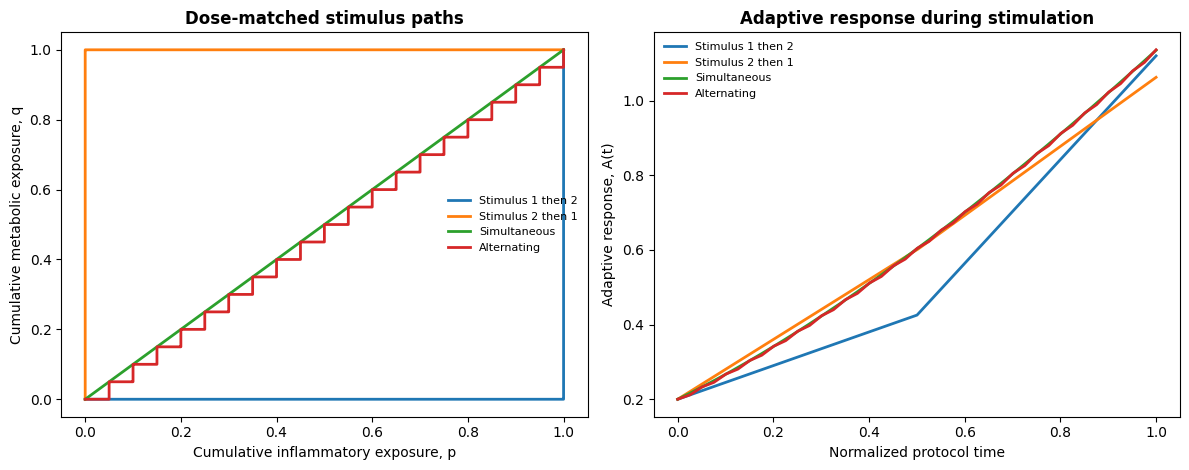

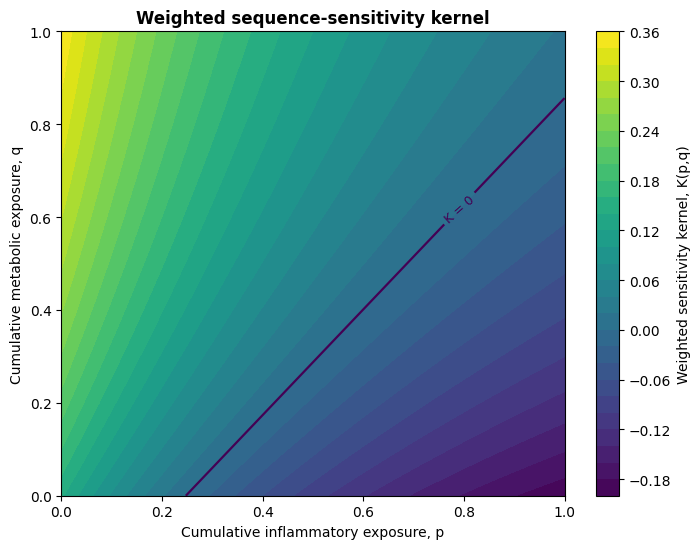

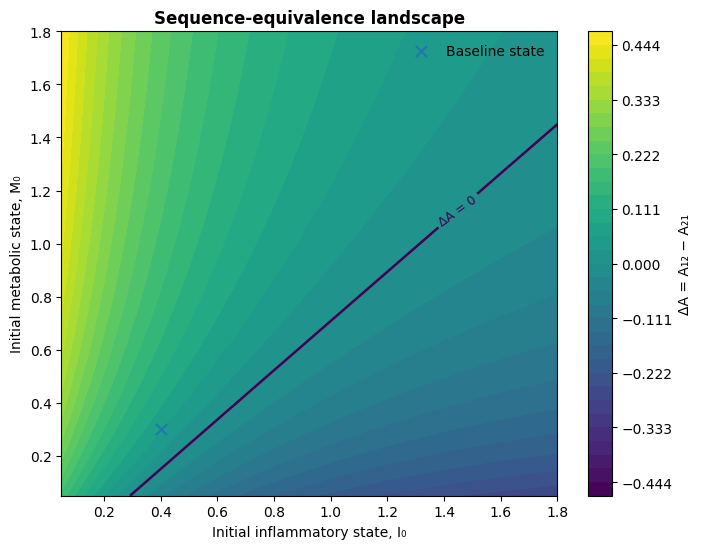

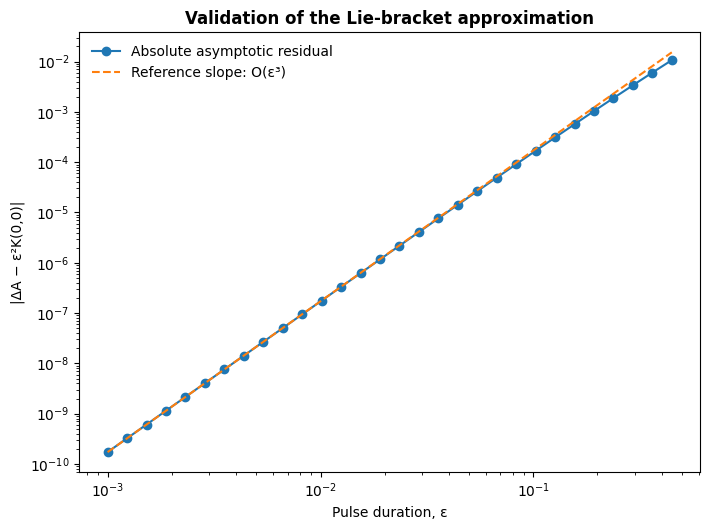

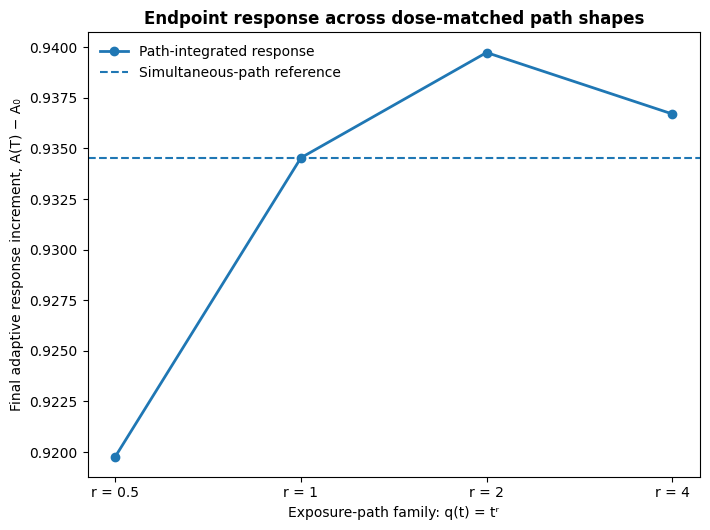


BIOLOGICAL SEQUENCE GEOMETRY
PHASE 1: NUMERICAL SIMULATIONS
--------------------------------------------------------------------
All parameters are illustrative and dimensionless.
No experimental data were used or fitted.

Protocol                     Final I    Final M      Final A
--------------------------------------------------------------------
Stimulus 1 then 2           1.200000   0.950000     1.119737
Stimulus 2 then 1           1.200000   0.950000     1.062162
Simultaneous                1.200000   0.950000     1.134536
Alternating                 1.200000   0.950000     1.135861

ANALYTICAL AND NUMERICAL CHECKS
--------------------------------------------------------------------
Exact A_12:                 1.119736842105
Numerical A_12:             1.119736842105
Error, protocol 1 -> 2:     1.621e-14

Exact A_21:                 1.062162162162
Numerical A_21:             1.062162162163
Error, protocol 2 -> 1:     4.894e-13

Exact sequence difference: 0.057574679943
Numerica

In [3]:

# ================================================================
# BIOLOGICAL SEQUENCE GEOMETRY
# Phase 1: Dose-matched stimulus sequences and weighted-area analysis
#
# Model:
#   dI/dt = a1*u1(t)
#   dM/dt = a2*u2(t)
#   dA/dt = c1*u1(t)*M/(KM + M)
#         + c2*u2(t)*I/(KI + I)
#
# All parameters are illustrative and dimensionless.
# They are not fitted to experimental measurements.
#
# Outputs:
#   Figure 1: Stimulus paths and adaptive response
#   Figure 2: Weighted sensitivity kernel
#   Figure 3: Sequence-equivalence landscape
#   Figure 4: Lie-bracket asymptotic validation
#   Figure 5: Dose-matched path-shape comparison
#
# ================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad


# ================================================================
# 1. OUTPUT DIRECTORY AND PARAMETERS
# ================================================================

OUTPUT_DIR = Path("biological_sequence_geometry_phase1_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PARAMS = {
    "a1": 0.80,
    "a2": 0.65,
    "c1": 0.90,
    "c2": 1.10,
    "KI": 0.70,
    "KM": 0.90,
    "I0": 0.40,
    "M0": 0.30,
    "A0": 0.20,
    "D1": 1.00,
    "D2": 1.00,
}

a1 = PARAMS["a1"]
a2 = PARAMS["a2"]
c1 = PARAMS["c1"]
c2 = PARAMS["c2"]
KI = PARAMS["KI"]
KM = PARAMS["KM"]

I0 = PARAMS["I0"]
M0 = PARAMS["M0"]
A0 = PARAMS["A0"]

D1 = PARAMS["D1"]
D2 = PARAMS["D2"]

N_STEPS = 20_000

# Parameter checks
if not all(v > 0 for v in [a1, a2, c1, c2, KI, KM, D1, D2]):
    raise ValueError("Rate, saturation, and dose parameters must be positive.")

if min(I0, M0, A0) < 0:
    raise ValueError("Initial states must be nonnegative.")


# ================================================================
# 2. MATHEMATICAL FUNCTIONS
# ================================================================

def weighted_kernel(p, q, I_init=I0, M_init=M0):
    """
    Signed weighted-area kernel.

    K(p,q) = dQ/dp - dP/dq
    """
    term_1 = (
        c2 * a1 * KI
        / (KI + I_init + a1 * p)**2
    )

    term_2 = (
        c1 * a2 * KM
        / (KM + M_init + a2 * q)**2
    )

    return term_1 - term_2


def exact_sequence_difference(
    dose1, dose2, I_init=I0, M_init=M0
):
    """
    Exact difference A_12 - A_21.

    Protocol 12: stimulus 1 followed by stimulus 2.
    Protocol 21: stimulus 2 followed by stimulus 1.

    Both protocols have identical cumulative doses.
    """

    increment_12 = (
        c1 * dose1 * M_init / (KM + M_init)
        + c2 * dose2 * (I_init + a1 * dose1)
        / (KI + I_init + a1 * dose1)
    )

    increment_21 = (
        c2 * dose2 * I_init / (KI + I_init)
        + c1 * dose1 * (M_init + a2 * dose2)
        / (KM + M_init + a2 * dose2)
    )

    return increment_12 - increment_21


def exact_final_A_protocol_12(dose1=D1, dose2=D2):
    """Exact final adaptive response for protocol 1 -> 2."""

    increment = (
        c1 * dose1 * M0 / (KM + M0)
        + c2 * dose2 * (I0 + a1 * dose1)
        / (KI + I0 + a1 * dose1)
    )

    return A0 + increment


def exact_final_A_protocol_21(dose1=D1, dose2=D2):
    """Exact final adaptive response for protocol 2 -> 1."""

    increment = (
        c2 * dose2 * I0 / (KI + I0)
        + c1 * dose1 * (M0 + a2 * dose2)
        / (KM + M0 + a2 * dose2)
    )

    return A0 + increment


# ================================================================
# 3. STIMULUS PROTOCOLS
# ================================================================

def path_protocol_12(t):
    """Stimulus 1 first, followed by stimulus 2."""

    if t <= 0.5:
        return 2.0 * t * D1, 0.0

    return D1, 2.0 * (t - 0.5) * D2


def path_protocol_21(t):
    """Stimulus 2 first, followed by stimulus 1."""

    if t <= 0.5:
        return 0.0, 2.0 * t * D2

    return 2.0 * (t - 0.5) * D1, D2


def path_simultaneous(t):
    """Both stimuli are applied simultaneously."""

    return t * D1, t * D2


def path_alternating(t, n_switches=20):
    """
    Alternating staircase protocol.

    The sequence is:
        stimulus 1, stimulus 2, stimulus 1, stimulus 2, ...

    Each input receives its complete prescribed dose.
    """

    if not 0.0 <= t <= 1.0:
        raise ValueError("Time must be between 0 and 1.")

    if t >= 1.0:
        return D1, D2

    n_segments = 2 * n_switches
    scaled_time = t * n_segments

    # Correct for floating-point values close to switching boundaries.
    nearest_boundary = round(scaled_time)

    if abs(scaled_time - nearest_boundary) < 1e-10:
        scaled_time = float(nearest_boundary)

    segment_index = min(
        int(np.floor(scaled_time)),
        n_segments - 1
    )

    fraction = scaled_time - segment_index
    fraction = min(max(fraction, 0.0), 1.0)

    if segment_index % 2 == 0:

        p = (
            (segment_index // 2)
            * D1 / n_switches
        )

        q = (
            (segment_index // 2)
            * D2 / n_switches
        )

        p += fraction * D1 / n_switches

    else:

        p = (
            ((segment_index + 1) // 2)
            * D1 / n_switches
        )

        q = (
            (segment_index // 2)
            * D2 / n_switches
        )

        q += fraction * D2 / n_switches

    return p, q


PROTOCOLS = {
    "Stimulus 1 then 2": path_protocol_12,
    "Stimulus 2 then 1": path_protocol_21,
    "Simultaneous": path_simultaneous,
    "Alternating": path_alternating,
}


# ================================================================
# 4. NUMERICAL LINE INTEGRATION
# ================================================================

def integrate_exposure_path(path_function, n_steps=N_STEPS):
    """
    Evaluate:

        dA = P(p,q) dp + Q(p,q) dq

    using the composite midpoint rule.

    The biological states I and M are recovered from
    cumulative exposures.
    """

    if n_steps < 2:
        raise ValueError("n_steps must be at least 2.")

    time = np.linspace(0.0, 1.0, n_steps + 1)

    path_values = np.array(
        [path_function(t) for t in time],
        dtype=float
    )

    p = path_values[:, 0]
    q = path_values[:, 1]

    # Cumulative exposure must never decrease.
    if np.any(np.diff(p) < -1e-12):
        raise ValueError("Inflammatory exposure is not monotonic.")

    if np.any(np.diff(q) < -1e-12):
        raise ValueError("Metabolic exposure is not monotonic.")

    A = np.empty(n_steps + 1)
    A[0] = A0

    for j in range(1, n_steps + 1):

        dp = p[j] - p[j - 1]
        dq = q[j] - q[j - 1]

        p_mid = 0.5 * (p[j] + p[j - 1])
        q_mid = 0.5 * (q[j] + q[j - 1])

        P = (
            c1 * (M0 + a2 * q_mid)
            / (KM + M0 + a2 * q_mid)
        )

        Q = (
            c2 * (I0 + a1 * p_mid)
            / (KI + I0 + a1 * p_mid)
        )

        A[j] = A[j - 1] + P * dp + Q * dq

    I = I0 + a1 * p
    M = M0 + a2 * q

    return {
        "time": time,
        "p": p,
        "q": q,
        "I": I,
        "M": M,
        "A": A,
    }


# Run all four protocols.
SIMULATION_RESULTS = {
    name: integrate_exposure_path(path)
    for name, path in PROTOCOLS.items()
}


# ================================================================
# 5. FIGURE 1 — STIMULUS PATHS AND RESPONSE TRAJECTORIES
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for name, result in SIMULATION_RESULTS.items():

    axes[0].plot(
        result["p"],
        result["q"],
        linewidth=2,
        label=name
    )

    axes[1].plot(
        result["time"],
        result["A"],
        linewidth=2,
        label=name
    )

axes[0].set_title(
    "Dose-matched stimulus paths",
    fontweight="bold"
)

axes[0].set_xlabel("Cumulative inflammatory exposure, p")
axes[0].set_ylabel("Cumulative metabolic exposure, q")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(False)

axes[1].set_title(
    "Adaptive response during stimulation",
    fontweight="bold"
)

axes[1].set_xlabel("Normalized protocol time")
axes[1].set_ylabel("Adaptive response, A(t)")
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure1_paths_and_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 6. FIGURE 2 — WEIGHTED SENSITIVITY KERNEL
# ================================================================

p_grid = np.linspace(0.0, D1, 250)
q_grid = np.linspace(0.0, D2, 250)

P_GRID, Q_GRID = np.meshgrid(p_grid, q_grid)

K_GRID = weighted_kernel(P_GRID, Q_GRID)

fig, ax = plt.subplots(figsize=(7.2, 5.6))

contour = ax.contourf(
    P_GRID,
    Q_GRID,
    K_GRID,
    levels=35
)

zero_contour = ax.contour(
    P_GRID,
    Q_GRID,
    K_GRID,
    levels=[0.0],
    linewidths=1.6
)

ax.clabel(
    zero_contour,
    fmt={0.0: "K = 0"},
    inline=True,
    fontsize=9
)

fig.colorbar(
    contour,
    ax=ax,
    label="Weighted sensitivity kernel, K(p,q)"
)

ax.set_title(
    "Weighted sequence-sensitivity kernel",
    fontweight="bold"
)

ax.set_xlabel("Cumulative inflammatory exposure, p")
ax.set_ylabel("Cumulative metabolic exposure, q")
ax.grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure2_weighted_kernel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 7. FIGURE 3 — SEQUENCE-EQUIVALENCE LANDSCAPE
# ================================================================

initial_I_values = np.linspace(0.05, 1.8, 220)
initial_M_values = np.linspace(0.05, 1.8, 220)

II, MM = np.meshgrid(
    initial_I_values,
    initial_M_values
)

DELTA_A_GRID = (
    c2 * a1 * KI * D1 * D2
    / ((KI + II) * (KI + II + a1 * D1))

    -

    c1 * a2 * KM * D1 * D2
    / ((KM + MM) * (KM + MM + a2 * D2))
)

fig, ax = plt.subplots(figsize=(7.2, 5.6))

max_abs_delta = np.max(np.abs(DELTA_A_GRID))

contour = ax.contourf(
    II,
    MM,
    DELTA_A_GRID,
    levels=np.linspace(
        -max_abs_delta,
        max_abs_delta,
        35
    )
)

zero_contour = ax.contour(
    II,
    MM,
    DELTA_A_GRID,
    levels=[0.0],
    linewidths=1.8
)

ax.clabel(
    zero_contour,
    fmt={0.0: "ΔA = 0"},
    inline=True,
    fontsize=9
)

ax.scatter(
    [I0],
    [M0],
    marker="x",
    s=65,
    label="Baseline state"
)

fig.colorbar(
    contour,
    ax=ax,
    label="ΔA = A₁₂ − A₂₁"
)

ax.set_title(
    "Sequence-equivalence landscape",
    fontweight="bold"
)

ax.set_xlabel("Initial inflammatory state, I₀")
ax.set_ylabel("Initial metabolic state, M₀")
ax.legend(frameon=False)
ax.grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure3_equivalence_landscape.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 8. FIGURE 4 — LIE-BRACKET ASYMPTOTIC VALIDATION
# ================================================================

epsilon_values = np.logspace(-3.0, -0.35, 30)

K_initial = weighted_kernel(0.0, 0.0)

exact_differences = np.array([
    exact_sequence_difference(eps, eps)
    for eps in epsilon_values
])

second_order_approximations = (
    epsilon_values**2 * K_initial
)

asymptotic_residuals = np.abs(
    exact_differences - second_order_approximations
)

# Estimate the slope over the first ten small-pulse values.
slope_estimate = np.polyfit(
    np.log(epsilon_values[:10]),
    np.log(asymptotic_residuals[:10]),
    deg=1
)[0]

reference_line = (
    asymptotic_residuals[5]
    * (epsilon_values / epsilon_values[5])**3
)

fig, ax = plt.subplots(figsize=(7.2, 5.4))

ax.loglog(
    epsilon_values,
    asymptotic_residuals,
    "o-",
    label="Absolute asymptotic residual"
)

ax.loglog(
    epsilon_values,
    reference_line,
    "--",
    label="Reference slope: O(ε³)"
)

ax.set_title(
    "Validation of the Lie-bracket approximation",
    fontweight="bold"
)

ax.set_xlabel("Pulse duration, ε")
ax.set_ylabel("|ΔA − ε²K(0,0)|")
ax.legend(frameon=False)
ax.grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure4_lie_bracket_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 9. FIGURE 5 — DOSE-MATCHED PATH-SHAPE COMPARISON
# ================================================================

def power_path_response_increment(exponent):
    """
    Exposure path:

        p(t) = D1*t
        q(t) = D2*t**exponent

    Every positive exponent has the same endpoint (D1,D2).
    """

    if exponent <= 0:
        raise ValueError("The path exponent must be positive.")

    def integrand(t):

        p = D1 * t
        q = D2 * t**exponent

        dp_dt = D1

        if t == 0.0:
            # Endpoint value does not affect the integral.
            dq_dt = 0.0
        else:
            dq_dt = (
                D2 * exponent
                * t**(exponent - 1.0)
            )

        P = (
            c1 * (M0 + a2 * q)
            / (KM + M0 + a2 * q)
        )

        Q = (
            c2 * (I0 + a1 * p)
            / (KI + I0 + a1 * p)
        )

        return P * dp_dt + Q * dq_dt

    value, estimated_error = quad(
        integrand,
        0.0,
        1.0,
        epsabs=1e-11,
        epsrel=1e-11,
        limit=300
    )

    return value, estimated_error


path_exponents = [0.5, 1.0, 2.0, 4.0]

path_shape_results = [
    power_path_response_increment(r)
    for r in path_exponents
]

path_shape_increments = [
    result[0] for result in path_shape_results
]

simultaneous_increment = path_shape_increments[
    path_exponents.index(1.0)
]

path_labels = [
    f"r = {r:g}"
    for r in path_exponents
]

fig, ax = plt.subplots(figsize=(7.2, 5.4))

ax.plot(
    path_labels,
    path_shape_increments,
    "o-",
    linewidth=2,
    label="Path-integrated response"
)

ax.axhline(
    simultaneous_increment,
    linestyle="--",
    linewidth=1.5,
    label="Simultaneous-path reference"
)

ax.set_title(
    "Endpoint response across dose-matched path shapes",
    fontweight="bold"
)

ax.set_xlabel("Exposure-path family: q(t) = tʳ")
ax.set_ylabel("Final adaptive response increment, A(T) − A₀")
ax.legend(frameon=False)
ax.grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure5_path_shape_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 10. INDEPENDENT WEIGHTED-AREA VERIFICATION
# ================================================================

# Green's theorem:
#
# A_12 - A_21 =
# integral_0^D1 integral_0^D2 K(p,q) dq dp
#
# The closed curve is formed by protocol 1->2 followed by
# the reverse of protocol 2->1. Its orientation is positive.

def inner_area_integral(p):

    value, _ = quad(
        lambda q: weighted_kernel(p, q),
        0.0,
        D2,
        epsabs=1e-12,
        epsrel=1e-12
    )

    return value


area_integral, area_quadrature_error = quad(
    inner_area_integral,
    0.0,
    D1,
    epsabs=1e-12,
    epsrel=1e-12
)

analytical_delta = exact_sequence_difference(D1, D2)

numerical_A12 = (
    SIMULATION_RESULTS["Stimulus 1 then 2"]["A"][-1]
)

numerical_A21 = (
    SIMULATION_RESULTS["Stimulus 2 then 1"]["A"][-1]
)

numerical_delta = numerical_A12 - numerical_A21

exact_A12 = exact_final_A_protocol_12(D1, D2)
exact_A21 = exact_final_A_protocol_21(D1, D2)

error_A12 = abs(numerical_A12 - exact_A12)
error_A21 = abs(numerical_A21 - exact_A21)

area_identity_error = abs(
    analytical_delta - area_integral
)


# ================================================================
# 11. NUMERICAL RESULTS AND DIAGNOSTICS
# ================================================================

print("\nBIOLOGICAL SEQUENCE GEOMETRY")
print("PHASE 1: NUMERICAL SIMULATIONS")
print("-" * 68)

print("All parameters are illustrative and dimensionless.")
print("No experimental data were used or fitted.\n")

print(
    f"{'Protocol':<25}"
    f"{'Final I':>11}"
    f"{'Final M':>11}"
    f"{'Final A':>13}"
)

print("-" * 68)

for name, result in SIMULATION_RESULTS.items():

    print(
        f"{name:<25}"
        f"{result['I'][-1]:>11.6f}"
        f"{result['M'][-1]:>11.6f}"
        f"{result['A'][-1]:>13.6f}"
    )


print("\nANALYTICAL AND NUMERICAL CHECKS")
print("-" * 68)

print(f"Exact A_12:                 {exact_A12:.12f}")
print(f"Numerical A_12:             {numerical_A12:.12f}")
print(f"Error, protocol 1 -> 2:     {error_A12:.3e}")

print()

print(f"Exact A_21:                 {exact_A21:.12f}")
print(f"Numerical A_21:             {numerical_A21:.12f}")
print(f"Error, protocol 2 -> 1:     {error_A21:.3e}")

print()

print(f"Exact sequence difference: {analytical_delta:.12f}")
print(f"Numerical path difference: {numerical_delta:.12f}")
print(f"Weighted-area integral:    {area_integral:.12f}")
print(f"Area identity discrepancy: {area_identity_error:.3e}")
print(f"Quadrature error estimate: {area_quadrature_error:.3e}")

print()

print(
    "Estimated small-pulse residual slope: "
    f"{slope_estimate:.4f}"
)

print("Expected asymptotic slope: approximately 3")


print("\nPATH-SHAPE RESULTS")
print("-" * 68)

for exponent, result in zip(
    path_exponents,
    path_shape_results
):

    value, error = result

    print(
        f"q(t)=t^{exponent:<4g}"
        f"  response increment={value:.10f}"
        f"  quadrature estimate={error:.2e}"
    )


# ================================================================
# 12. AUTOMATIC VALIDATION TESTS
# ================================================================

# All protocols must end at the same cumulative doses.
for name, result in SIMULATION_RESULTS.items():

    assert np.isclose(result["p"][-1], D1, atol=1e-10), (
        f"Incorrect inflammatory dose in {name}"
    )

    assert np.isclose(result["q"][-1], D2, atol=1e-10), (
        f"Incorrect metabolic dose in {name}"
    )

    assert np.all(np.diff(result["p"]) >= -1e-12), (
        f"Inflammatory exposure decreased in {name}"
    )

    assert np.all(np.diff(result["q"]) >= -1e-12), (
        f"Metabolic exposure decreased in {name}"
    )

# The numerical integration must agree with the exact expressions.
assert error_A12 < 1e-8
assert error_A21 < 1e-8

# The weighted-area identity must agree with the exact formula.
assert area_identity_error < 1e-9

# The asymptotic slope should be close to three.
assert 2.8 < slope_estimate < 3.2

print("\nVALIDATION")
print("-" * 68)
print("All cumulative-dose checks passed.")
print("All monotonicity checks passed.")
print("Exact endpoint comparisons passed.")
print("Weighted-area identity check passed.")
print("Small-pulse asymptotic check passed.")


# ================================================================
# 13. SAVE PARAMETER AND RESULT SUMMARY
# ================================================================

summary_path = OUTPUT_DIR / "simulation_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:

    file.write("BIOLOGICAL SEQUENCE GEOMETRY — PHASE 1\n")
    file.write("Illustrative dimensionless model\n")
    file.write("No experimental data used or fitted.\n\n")

    file.write("PARAMETERS\n")

    for key, value in PARAMS.items():
        file.write(f"{key} = {value}\n")

    file.write("\nENDPOINT RESULTS\n")

    for name, result in SIMULATION_RESULTS.items():

        file.write(
            f"{name}: "
            f"I={result['I'][-1]:.12f}, "
            f"M={result['M'][-1]:.12f}, "
            f"A={result['A'][-1]:.12f}\n"
        )

    file.write("\nMATHEMATICAL CHECKS\n")
    file.write(f"Exact A12 = {exact_A12:.12f}\n")
    file.write(f"Numerical A12 = {numerical_A12:.12f}\n")
    file.write(f"Exact A21 = {exact_A21:.12f}\n")
    file.write(f"Numerical A21 = {numerical_A21:.12f}\n")
    file.write(f"Exact Delta A = {analytical_delta:.12f}\n")
    file.write(f"Area integral = {area_integral:.12f}\n")
    file.write(
        f"Area identity discrepancy = "
        f"{area_identity_error:.3e}\n"
    )
    file.write(
        f"Estimated asymptotic slope = "
        f"{slope_estimate:.6f}\n"
    )

print("\nOUTPUT FILES")
print("-" * 68)
print(f"Folder: {OUTPUT_DIR.resolve()}")

for filename in sorted(OUTPUT_DIR.glob("*.png")):
    print(" -", filename.name)

print(" -", summary_path.name)

print("\nSimulation completed successfully.")


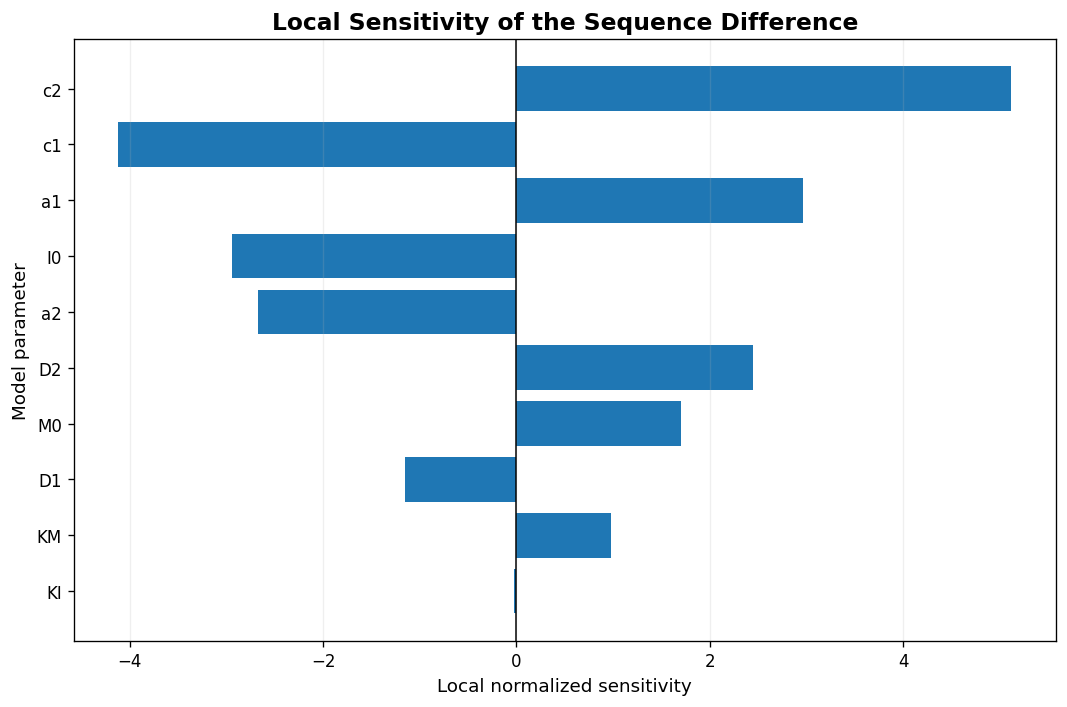

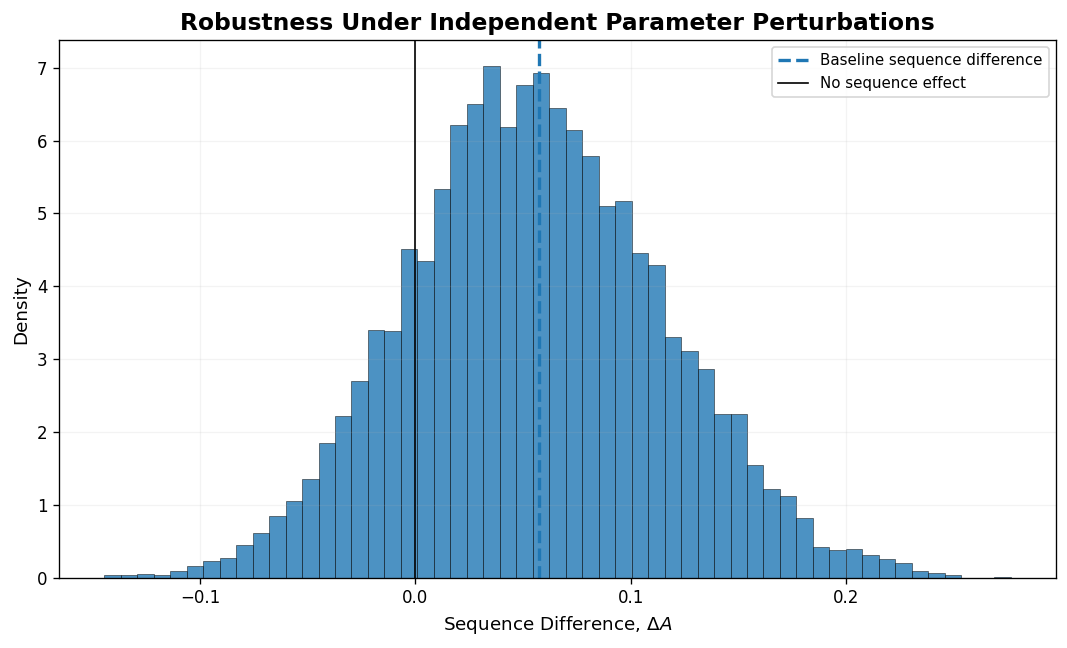

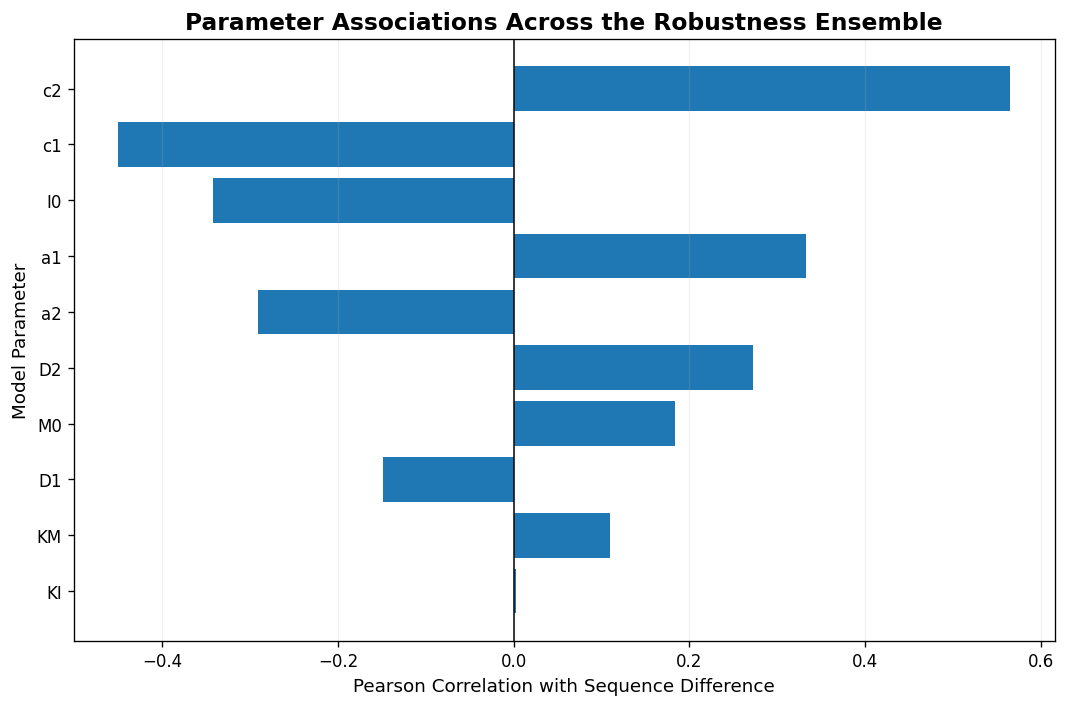

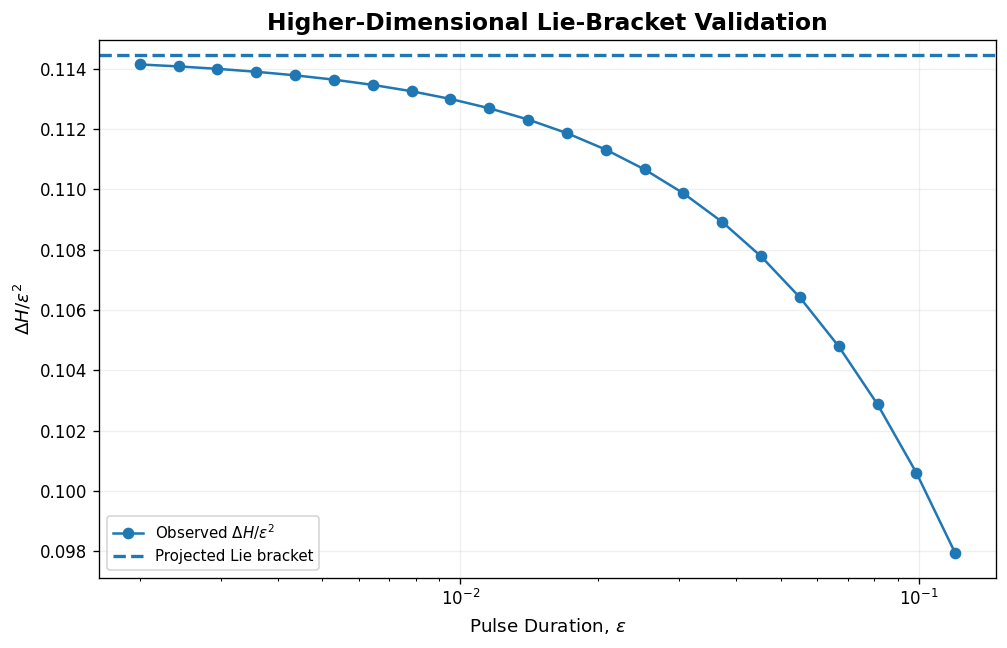

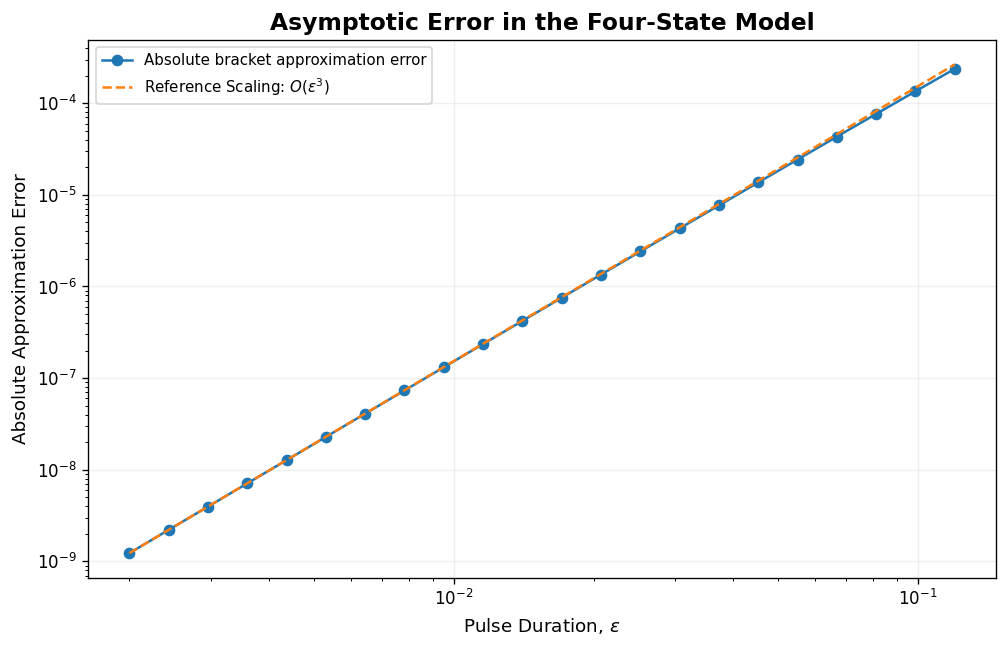


PHASE 2 COMPLETED

BASELINE
-----------------------------------------------------------------
Baseline sequence difference: 0.057574679943

LOCAL NORMALIZED SENSITIVITY
-----------------------------------------------------------------
KI      : -0.024494
KM      : +0.974137
D1      : -1.155457
M0      : +1.697782
D2      : +2.447290
a2      : -2.671920
I0      : -2.939259
a1      : +2.963753
c1      : -4.119209
c2      : +5.119209

ROBUSTNESS ANALYSIS
-----------------------------------------------------------------
Monte Carlo samples: 10000
Positive sequence difference: 82.66%
Negative sequence difference: 17.34%
Sign differs from baseline: 17.34%

Sequence-difference quantiles:
[-0.05699628  0.01579478  0.05405888  0.09544786  0.17469833]

FOUR-STATE LIE-BRACKET TEST
-----------------------------------------------------------------
Lie bracket vector: [ 0.          0.          0.14346591 -0.04837241]
Projected bracket: 0.114442464993
Smallest-pulse observed ratio: 0.114135349560
Sm

In [7]:

# ============================================================
# BIOLOGICAL SEQUENCE GEOMETRY
# PHASE 2
# Sensitivity, Robustness and Higher-Dimensional Analysis
#
# All parameters are illustrative and dimensionless.
# No experimental data are used or fitted.
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp


# ============================================================
# 1. GENERAL SETTINGS
# ============================================================

OUTPUT_DIR = "biological_sequence_geometry_phase2_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 20261117
N_MONTE_CARLO = 10000
PERTURBATION_RANGE = 0.20

# Consistent scientific figure formatting
plt.rcParams.update({
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300
})


# ============================================================
# 2. BASELINE MODEL PARAMETERS
# ============================================================

PARAMS = {
    "a1": 0.80,
    "a2": 0.65,
    "c1": 0.90,
    "c2": 1.10,
    "KI": 0.70,
    "KM": 0.90,
    "I0": 0.40,
    "M0": 0.30,
    "D1": 1.00,
    "D2": 1.00
}

A0 = 0.20

PARAMETER_NAMES = list(PARAMS.keys())


# ============================================================
# 3. ANALYTICAL SEQUENCE DIFFERENCE
# ============================================================

def sequence_difference(p):

    a1 = p["a1"]
    a2 = p["a2"]

    c1 = p["c1"]
    c2 = p["c2"]

    KI = p["KI"]
    KM = p["KM"]

    I0 = p["I0"]
    M0 = p["M0"]

    D1 = p["D1"]
    D2 = p["D2"]

    term_1 = (
        c2 * a1 * KI * D1 * D2
        / (
            (KI + I0)
            * (KI + I0 + a1 * D1)
        )
    )

    term_2 = (
        c1 * a2 * KM * D1 * D2
        / (
            (KM + M0)
            * (KM + M0 + a2 * D2)
        )
    )

    return term_1 - term_2


BASELINE_DELTA = sequence_difference(PARAMS)

if abs(BASELINE_DELTA) < 1e-12:
    raise RuntimeError(
        "Baseline sequence difference is too close to zero."
    )


# ============================================================
# 4. LOCAL PARAMETER SENSITIVITY
# ============================================================

def local_elasticity(
    p,
    parameter_name,
    relative_step=1e-5
):

    p_plus = p.copy()
    p_minus = p.copy()

    value = p[parameter_name]
    step = relative_step * value

    p_plus[parameter_name] = value + step
    p_minus[parameter_name] = value - step

    derivative = (
        sequence_difference(p_plus)
        - sequence_difference(p_minus)
    ) / (2.0 * step)

    return (
        value
        / sequence_difference(p)
    ) * derivative


ELASTICITIES = {
    name: local_elasticity(PARAMS, name)
    for name in PARAMETER_NAMES
}

sorted_sensitivity = sorted(
    ELASTICITIES.items(),
    key=lambda item: abs(item[1])
)

sensitivity_names = [
    item[0] for item in sorted_sensitivity
]

sensitivity_values = [
    item[1] for item in sorted_sensitivity
]


# Figure 1: Local sensitivity

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    sensitivity_names,
    sensitivity_values
)

ax.axvline(
    0,
    color="black",
    linewidth=0.9
)

ax.set_xlabel(
    "Local normalized sensitivity"
)

ax.set_ylabel(
    "Model parameter"
)

ax.set_title(
    "Local Sensitivity of the Sequence Difference",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="x",
    alpha=0.20
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure1_local_sensitivity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 5. PARAMETER ROBUSTNESS ANALYSIS
# ============================================================

rng = np.random.default_rng(SEED)

sampled_differences = np.zeros(
    N_MONTE_CARLO
)

sampled_parameters = {
    name: np.zeros(N_MONTE_CARLO)
    for name in PARAMETER_NAMES
}

for i in range(N_MONTE_CARLO):

    sampled = {}

    for name, baseline_value in PARAMS.items():

        lower = (
            baseline_value
            * (1.0 - PERTURBATION_RANGE)
        )

        upper = (
            baseline_value
            * (1.0 + PERTURBATION_RANGE)
        )

        value = rng.uniform(lower, upper)

        sampled[name] = value

        sampled_parameters[name][i] = value

    sampled_differences[i] = sequence_difference(
        sampled
    )


positive_fraction = np.mean(
    sampled_differences > 0
)

negative_fraction = np.mean(
    sampled_differences < 0
)

sign_change_fraction = np.mean(
    np.sign(sampled_differences)
    != np.sign(BASELINE_DELTA)
)

quantiles = np.quantile(
    sampled_differences,
    [
        0.025,
        0.25,
        0.50,
        0.75,
        0.975
    ]
)


# Figure 2: Robustness distribution

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.hist(
    sampled_differences,
    bins=55,
    density=True,
    alpha=0.80,
    edgecolor="black",
    linewidth=0.35
)

ax.axvline(
    BASELINE_DELTA,
    linestyle="--",
    linewidth=2,
    label="Baseline sequence difference"
)

ax.axvline(
    0,
    color="black",
    linewidth=1,
    label="No sequence effect"
)

ax.set_xlabel(
    r"Sequence Difference, $\Delta A$"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "Robustness Under Independent Parameter Perturbations",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.15)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure2_robustness_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 6. PARAMETER ASSOCIATIONS
# ============================================================

correlations = {}

for name in PARAMETER_NAMES:

    correlations[name] = np.corrcoef(
        sampled_parameters[name],
        sampled_differences
    )[0, 1]


sorted_correlations = sorted(
    correlations.items(),
    key=lambda item: abs(item[1])
)

corr_names = [
    item[0] for item in sorted_correlations
]

corr_values = [
    item[1] for item in sorted_correlations
]


# Figure 3: Parameter correlations

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    corr_names,
    corr_values
)

ax.axvline(
    0,
    color="black",
    linewidth=0.9
)

ax.set_xlabel(
    "Pearson Correlation with Sequence Difference"
)

ax.set_ylabel(
    "Model Parameter"
)

ax.set_title(
    "Parameter Associations Across the Robustness Ensemble",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="x",
    alpha=0.20
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure3_parameter_correlations.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 7. FOUR-STATE CONTROL-AFFINE MODEL
# ============================================================

"""
Four-state system:

    x = (I, M, A, Z)

    dx/dt = u1 F1(x) + u2 F2(x)

Observable:

    H(x) = A + rho Z

The additional state Z represents a second adaptive
component. This is an illustrative mathematical extension.
"""

P4 = {
    "a1": 0.80,
    "a2": 0.65,
    "c1": 0.90,
    "c2": 1.10,
    "KI": 0.70,
    "KM": 0.90,
    "r1": 0.35,
    "r2": 0.25,
    "KZ": 0.80,
    "LZ": 1.00,
    "rho": 0.60
}


def F1(x):

    I, M, A, Z = x

    return np.array([
        P4["a1"],
        0.0,
        P4["c1"] * M / (P4["KM"] + M),
        P4["r1"] * M / (P4["KZ"] + M)
    ])


def F2(x):

    I, M, A, Z = x

    return np.array([
        0.0,
        P4["a2"],
        P4["c2"] * I / (P4["KI"] + I),
        P4["r2"] * I / (P4["LZ"] + I)
    ])


def observable(x):

    return (
        x[2]
        + P4["rho"] * x[3]
    )


def numerical_jacobian(
    vector_field,
    x,
    h=1e-6
):

    n = len(x)

    J = np.zeros((n, n))

    for j in range(n):

        x_plus = x.copy()
        x_minus = x.copy()

        x_plus[j] += h
        x_minus[j] -= h

        J[:, j] = (
            vector_field(x_plus)
            - vector_field(x_minus)
        ) / (2.0 * h)

    return J


def lie_bracket(
    F1_function,
    F2_function,
    x
):

    J1 = numerical_jacobian(
        F1_function,
        x
    )

    J2 = numerical_jacobian(
        F2_function,
        x
    )

    # Convention:
    # [F1,F2] = DF2*F1 - DF1*F2

    return (
        J2 @ F1_function(x)
        - J1 @ F2_function(x)
    )


X0 = np.array([
    0.40,
    0.30,
    0.20,
    0.15
])

bracket_vector = lie_bracket(
    F1,
    F2,
    X0
)

grad_H = np.array([
    0.0,
    0.0,
    1.0,
    P4["rho"]
])

projected_bracket = float(
    grad_H @ bracket_vector
)


# ============================================================
# 8. NUMERICAL ORDER-OF-APPLICATION EXPERIMENT
# ============================================================

def apply_single_control(
    x_initial,
    vector_field,
    duration
):

    def rhs(t, x):
        return vector_field(x)

    result = solve_ivp(
        rhs,
        (0.0, duration),
        x_initial,
        method="DOP853",
        rtol=1e-11,
        atol=1e-13
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.y[:, -1]


def apply_protocol_12(epsilon):

    after_first = apply_single_control(
        X0,
        F1,
        epsilon
    )

    after_second = apply_single_control(
        after_first,
        F2,
        epsilon
    )

    return after_second


def apply_protocol_21(epsilon):

    after_first = apply_single_control(
        X0,
        F2,
        epsilon
    )

    after_second = apply_single_control(
        after_first,
        F1,
        epsilon
    )

    return after_second


EPSILONS = np.geomspace(
    0.002,
    0.12,
    22
)

observed_differences = []
bracket_predictions = []
asymptotic_errors = []

for epsilon in EPSILONS:

    x12 = apply_protocol_12(epsilon)
    x21 = apply_protocol_21(epsilon)

    delta_H = (
        observable(x12)
        - observable(x21)
    )

    prediction = (
        epsilon**2
        * projected_bracket
    )

    observed_differences.append(delta_H)

    bracket_predictions.append(
        prediction
    )

    asymptotic_errors.append(
        abs(delta_H - prediction)
    )


observed_differences = np.array(
    observed_differences
)

bracket_predictions = np.array(
    bracket_predictions
)

asymptotic_errors = np.array(
    asymptotic_errors
)


# ============================================================
# 9. LIE-BRACKET VALIDATION
# ============================================================

bracket_ratios = (
    observed_differences
    / EPSILONS**2
)


# Figure 4: Higher-dimensional bracket

fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.semilogx(
    EPSILONS,
    bracket_ratios,
    "o-",
    label=r"Observed $\Delta H/\epsilon^2$"
)

ax.axhline(
    projected_bracket,
    linestyle="--",
    linewidth=2,
    label="Projected Lie bracket"
)

ax.set_xlabel(
    r"Pulse Duration, $\epsilon$"
)

ax.set_ylabel(
    r"$\Delta H/\epsilon^2$"
)

ax.set_title(
    "Higher-Dimensional Lie-Bracket Validation",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.20)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure4_higher_dimensional_bracket.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 10. ASYMPTOTIC ERROR ANALYSIS
# ============================================================

reference = (
    asymptotic_errors[0]
    * (EPSILONS / EPSILONS[0])**3
)


# Figure 5: Bracket approximation error

fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.loglog(
    EPSILONS,
    asymptotic_errors,
    "o-",
    label="Absolute bracket approximation error"
)

ax.loglog(
    EPSILONS,
    reference,
    "--",
    label=r"Reference Scaling: $O(\epsilon^3)$"
)

ax.set_xlabel(
    r"Pulse Duration, $\epsilon$"
)

ax.set_ylabel(
    "Absolute Approximation Error"
)

ax.set_title(
    "Asymptotic Error in the Four-State Model",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.20)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure5_bracket_error.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 11. AUTOMATED VALIDATION
# ============================================================

for name, value in PARAMS.items():

    assert value > 0, (
        f"Non-positive parameter: {name}"
    )


assert np.isfinite(BASELINE_DELTA)

assert np.all(
    np.isfinite(sampled_differences)
)

assert np.all(
    np.isfinite(observed_differences)
)

assert np.all(
    np.isfinite(asymptotic_errors)
)


small_epsilon_count = 5

small_epsilon_ratios = (
    bracket_ratios[:small_epsilon_count]
)

relative_bracket_errors = (
    np.abs(
        small_epsilon_ratios
        - projected_bracket
    )
    / max(
        abs(projected_bracket),
        1e-12
    )
)


assert relative_bracket_errors[0] < 0.05, (
    "Small-pulse Lie-bracket check did not meet "
    "the 5% relative-error tolerance."
)


# ============================================================
# 12. SAVE NUMERICAL SUMMARY
# ============================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "phase2_simulation_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "BIOLOGICAL SEQUENCE GEOMETRY\n"
    )

    file.write(
        "PHASE 2: SENSITIVITY AND ROBUSTNESS\n"
    )

    file.write("=" * 72 + "\n\n")

    file.write(
        "All parameters are illustrative and dimensionless.\n"
    )

    file.write(
        "No experimental data were used or fitted.\n\n"
    )

    file.write(
        "BASELINE PARAMETERS\n"
    )

    file.write("-" * 72 + "\n")

    for name, value in PARAMS.items():

        file.write(
            f"{name:10s}: {value:.8f}\n"
        )

    file.write(
        f"\nBaseline sequence difference: "
        f"{BASELINE_DELTA:.12f}\n\n"
    )

    file.write(
        "LOCAL NORMALIZED SENSITIVITIES\n"
    )

    file.write("-" * 72 + "\n")

    for name, value in sorted_sensitivity:

        file.write(
            f"{name:10s}: {value:+.8f}\n"
        )

    file.write(
        "\nROBUSTNESS ANALYSIS\n"
    )

    file.write("-" * 72 + "\n")

    file.write(
        f"Monte Carlo samples: {N_MONTE_CARLO}\n"
    )

    file.write(
        f"Independent parameter range: "
        f"+/- {100*PERTURBATION_RANGE:.1f}%\n"
    )

    file.write(
        f"Positive sequence difference: "
        f"{100*positive_fraction:.2f}%\n"
    )

    file.write(
        f"Negative sequence difference: "
        f"{100*negative_fraction:.2f}%\n"
    )

    file.write(
        f"Sign differs from baseline: "
        f"{100*sign_change_fraction:.2f}%\n"
    )

    file.write(
        "Quantiles (2.5%, 25%, 50%, 75%, 97.5%):\n"
    )

    file.write(
        np.array2string(
            quantiles,
            precision=10,
            separator=", "
        ) + "\n\n"
    )

    file.write(
        "FOUR-STATE LIE-BRACKET TEST\n"
    )

    file.write("-" * 72 + "\n")

    file.write(
        "Initial state (I, M, A, Z): "
        + np.array2string(
            X0,
            precision=8
        ) + "\n"
    )

    file.write(
        "Lie bracket vector: "
        + np.array2string(
            bracket_vector,
            precision=10
        ) + "\n"
    )

    file.write(
        f"Projected bracket: "
        f"{projected_bracket:.12f}\n"
    )

    file.write(
        f"Smallest-pulse observed ratio: "
        f"{bracket_ratios[0]:.12f}\n"
    )

    file.write(
        f"Smallest-pulse relative error: "
        f"{relative_bracket_errors[0]:.6e}\n\n"
    )

    file.write(
        "VALIDATION\n"
    )

    file.write("-" * 72 + "\n")

    file.write(
        "All parameter positivity checks passed.\n"
    )

    file.write(
        "All numerical finiteness checks passed.\n"
    )

    file.write(
        "Small-pulse Lie-bracket tolerance check passed.\n"
    )


# ============================================================
# 13. DISPLAY RESULTS
# ============================================================

print("\nPHASE 2 COMPLETED")
print("=" * 65)

print("\nBASELINE")
print("-" * 65)

print(
    f"Baseline sequence difference: "
    f"{BASELINE_DELTA:.12f}"
)

print("\nLOCAL NORMALIZED SENSITIVITY")
print("-" * 65)

for name, value in sorted_sensitivity:

    print(
        f"{name:8s}: {value:+.6f}"
    )

print("\nROBUSTNESS ANALYSIS")
print("-" * 65)

print(
    f"Monte Carlo samples: {N_MONTE_CARLO}"
)

print(
    f"Positive sequence difference: "
    f"{100*positive_fraction:.2f}%"
)

print(
    f"Negative sequence difference: "
    f"{100*negative_fraction:.2f}%"
)

print(
    f"Sign differs from baseline: "
    f"{100*sign_change_fraction:.2f}%"
)

print("\nSequence-difference quantiles:")
print(quantiles)

print("\nFOUR-STATE LIE-BRACKET TEST")
print("-" * 65)

print(
    "Lie bracket vector:",
    bracket_vector
)

print(
    f"Projected bracket: "
    f"{projected_bracket:.12f}"
)

print(
    "Smallest-pulse observed ratio:",
    f"{bracket_ratios[0]:.12f}"
)

print(
    "Smallest-pulse relative error:",
    f"{relative_bracket_errors[0]:.6e}"
)

print("\nVALIDATION")
print("-" * 65)

print(
    "All parameter positivity checks passed."
)

print(
    "All numerical finiteness checks passed."
)

print(
    "Small-pulse Lie-bracket tolerance check passed."
)

print("\nOUTPUT FOLDER")
print("-" * 65)

print(
    os.path.abspath(OUTPUT_DIR)
)

print("\nGENERATED FILES")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(" -", filename)

print("\nAll Phase 2 calculations completed.")


In [9]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


BASELINE SEQUENCE DIFFERENCE
Delta A = 0.057574679943


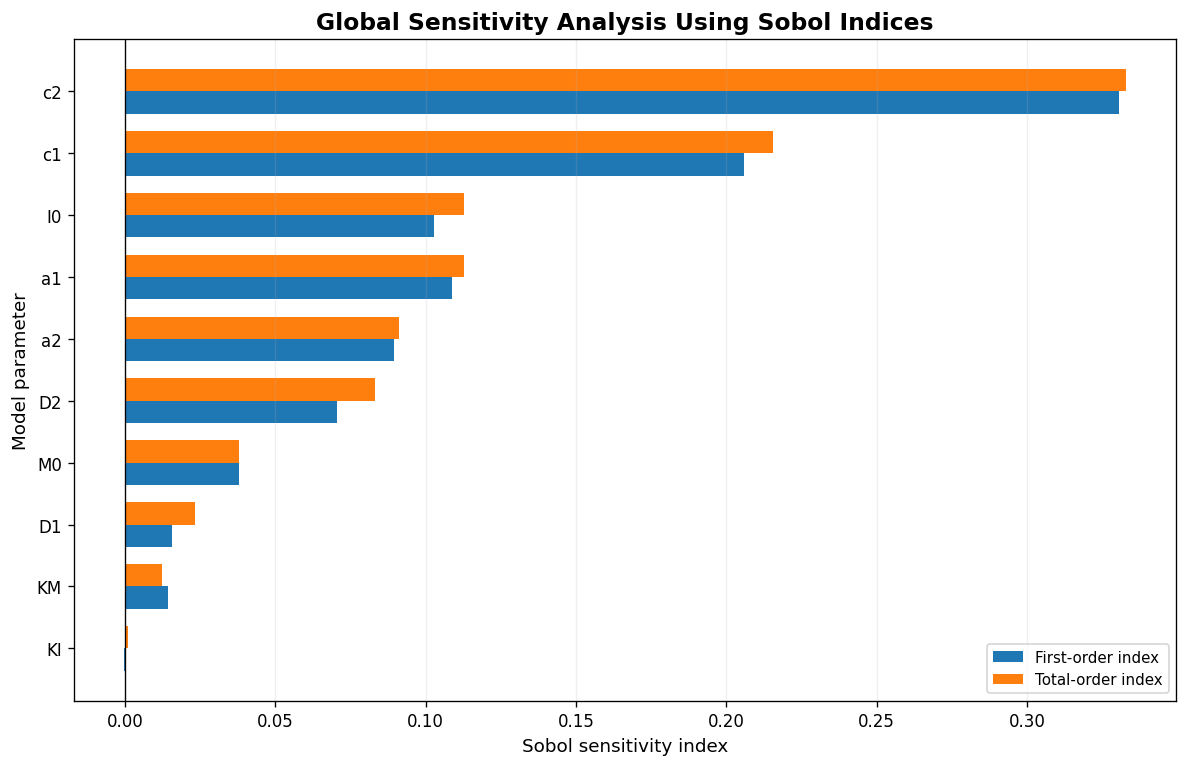

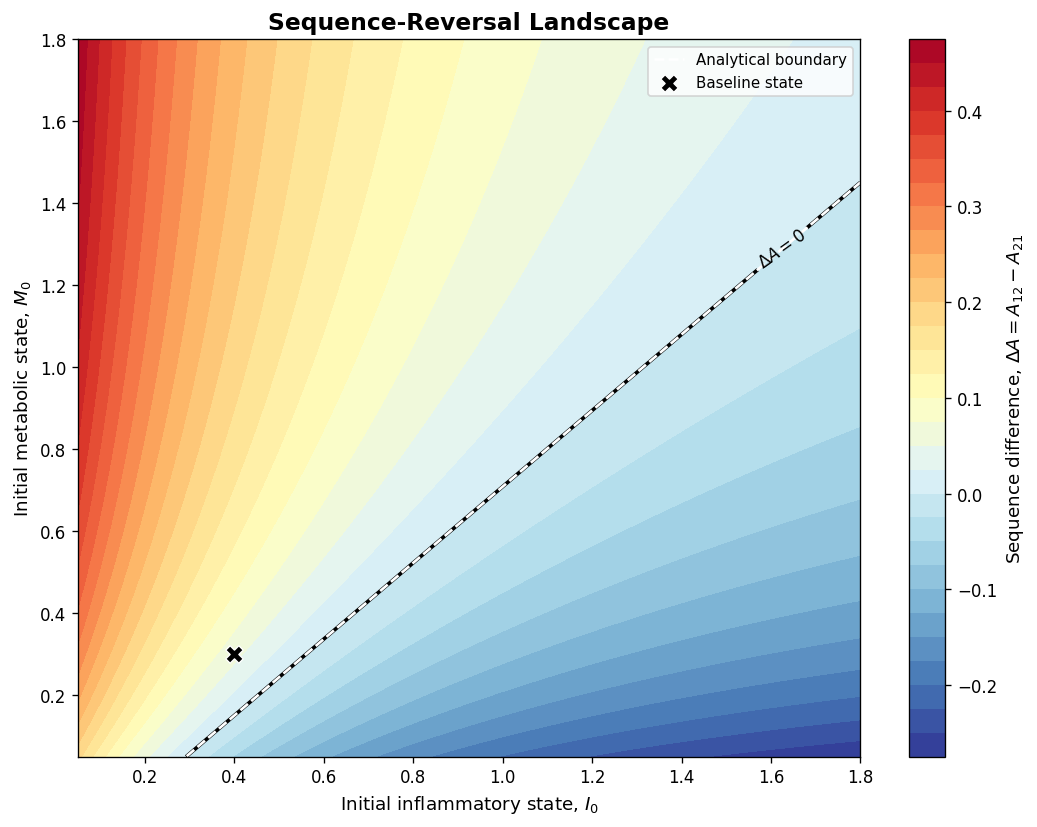

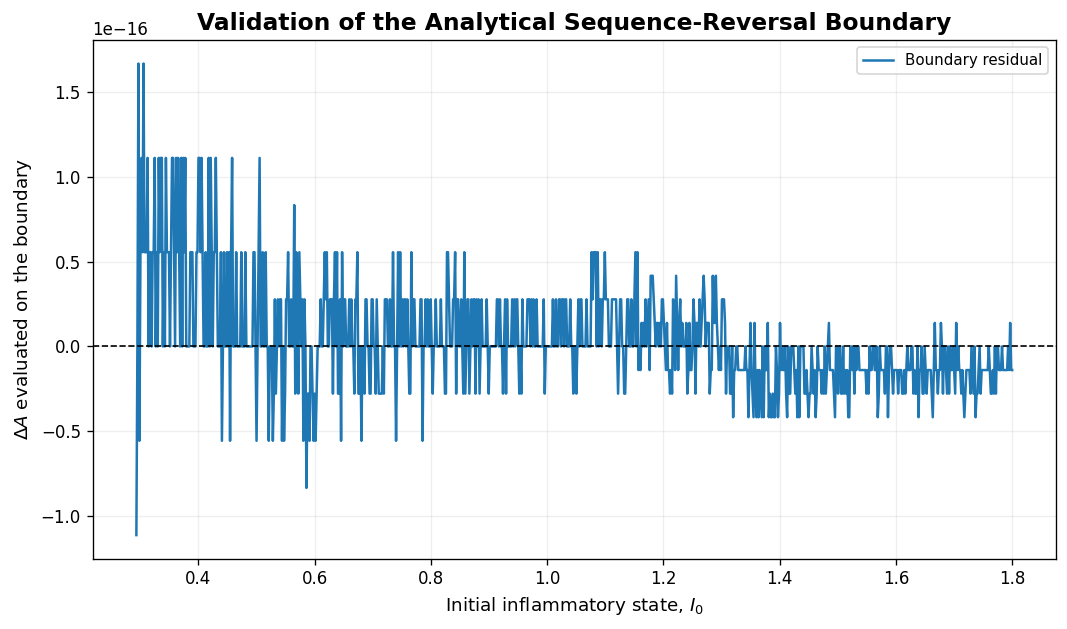


PHASE 3 COMPLETED

BASELINE
---------------------------------------------------------------------------
Baseline sequence difference: 0.057574679943

GLOBAL SOBOL INDICES
---------------------------------------------------------------------------
Parameter        First-order     Total-order    ST stability
a1                  0.108666        0.112713        0.001479
a2                  0.089461        0.090992        0.003141
c1                  0.205880        0.215566        0.005305
c2                  0.330631        0.332836        0.003834
KI                 -0.000459        0.000863        0.000058
KM                  0.014215        0.012176        0.000098
I0                  0.102615        0.112847        0.000963
M0                  0.038049        0.037788        0.000851
D1                  0.015710        0.023372        0.000229
D2                  0.070371        0.083139        0.001364

SEQUENCE-REVERSAL BOUNDARY
-----------------------------------------------------

In [11]:

# ============================================================
# BIOLOGICAL SEQUENCE GEOMETRY
# PHASE 3
#
# GLOBAL SENSITIVITY ANALYSIS
# SEQUENCE-REVERSAL BOUNDARY
# ANALYTICAL BOUNDARY VALIDATION
#
# All parameters are illustrative and dimensionless.
# No experimental data are used or fitted.
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

OUTPUT_DIR = "biological_sequence_geometry_phase3_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 20261118

N_SOBOL = 16384

PERTURBATION_RANGE = 0.20

plt.rcParams.update({
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300
})


# ============================================================
# 2. BASELINE PARAMETERS
# ============================================================

PARAMS = {
    "a1": 0.80,
    "a2": 0.65,
    "c1": 0.90,
    "c2": 1.10,
    "KI": 0.70,
    "KM": 0.90,
    "I0": 0.40,
    "M0": 0.30,
    "D1": 1.00,
    "D2": 1.00
}

PARAMETER_NAMES = list(PARAMS.keys())

BASELINE_DELTA = None


# ============================================================
# 3. EXACT SEQUENCE-DIFFERENCE FUNCTION
# ============================================================

def sequence_difference(p):

    term_1 = (
        p["c2"]
        * p["a1"]
        * p["KI"]
        * p["D1"]
        * p["D2"]
        /
        (
            (p["KI"] + p["I0"])
            * (
                p["KI"]
                + p["I0"]
                + p["a1"] * p["D1"]
            )
        )
    )

    term_2 = (
        p["c1"]
        * p["a2"]
        * p["KM"]
        * p["D1"]
        * p["D2"]
        /
        (
            (p["KM"] + p["M0"])
            * (
                p["KM"]
                + p["M0"]
                + p["a2"] * p["D2"]
            )
        )
    )

    return term_1 - term_2


BASELINE_DELTA = sequence_difference(PARAMS)

if not np.isfinite(BASELINE_DELTA):
    raise RuntimeError("Invalid baseline sequence difference.")

print("BASELINE SEQUENCE DIFFERENCE")
print(f"Delta A = {BASELINE_DELTA:.12f}")


# ============================================================
# 4. VECTORISED MODEL FOR GLOBAL SENSITIVITY
# ============================================================

def sequence_difference_array(X):
    """
    X has shape (n_samples, n_parameters).

    The column order follows PARAMETER_NAMES.
    """

    values = {
        name: X[:, j]
        for j, name in enumerate(PARAMETER_NAMES)
    }

    term_1 = (
        values["c2"]
        * values["a1"]
        * values["KI"]
        * values["D1"]
        * values["D2"]
        /
        (
            (values["KI"] + values["I0"])
            * (
                values["KI"]
                + values["I0"]
                + values["a1"] * values["D1"]
            )
        )
    )

    term_2 = (
        values["c1"]
        * values["a2"]
        * values["KM"]
        * values["D1"]
        * values["D2"]
        /
        (
            (values["KM"] + values["M0"])
            * (
                values["KM"]
                + values["M0"]
                + values["a2"] * values["D2"]
            )
        )
    )

    return term_1 - term_2


# ============================================================
# 5. SALTELLI GLOBAL SENSITIVITY ANALYSIS
# ============================================================

def calculate_sobol_indices(
    N,
    parameter_names,
    baseline_parameters,
    perturbation_range,
    seed
):
    """
    Independent uniform parameter sampling.

    First-order estimator:
        S_i = mean(Y_B * (Y_ABi - Y_A)) / Var(Y)

    Total-order estimator:
        ST_i = mean((Y_A - Y_ABi)^2) / (2 Var(Y))

    These are Saltelli/Jansen-style estimators.
    """

    rng = np.random.default_rng(seed)

    dimension = len(parameter_names)

    lower = np.array([
        baseline_parameters[name]
        * (1.0 - perturbation_range)
        for name in parameter_names
    ])

    upper = np.array([
        baseline_parameters[name]
        * (1.0 + perturbation_range)
        for name in parameter_names
    ])

    A_unit = rng.random((N, dimension))
    B_unit = rng.random((N, dimension))

    A = lower + A_unit * (upper - lower)
    B = lower + B_unit * (upper - lower)

    Y_A = sequence_difference_array(A)
    Y_B = sequence_difference_array(B)

    variance = np.var(
        np.concatenate([Y_A, Y_B]),
        ddof=1
    )

    if variance <= 0:
        raise RuntimeError(
            "Output variance is zero. Sobol indices undefined."
        )

    first_order = np.zeros(dimension)
    total_order = np.zeros(dimension)

    for i in range(dimension):

        AB_i = A.copy()

        AB_i[:, i] = B[:, i]

        Y_AB_i = sequence_difference_array(AB_i)

        first_order[i] = np.mean(
            Y_B * (Y_AB_i - Y_A)
        ) / variance

        total_order[i] = (
            np.mean((Y_A - Y_AB_i)**2)
            / (2.0 * variance)
        )

    return {
        "first_order": first_order,
        "total_order": total_order,
        "variance": variance,
        "lower": lower,
        "upper": upper
    }


sobol = calculate_sobol_indices(
    N=N_SOBOL,
    parameter_names=PARAMETER_NAMES,
    baseline_parameters=PARAMS,
    perturbation_range=PERTURBATION_RANGE,
    seed=SEED
)

S1 = sobol["first_order"]
ST = sobol["total_order"]

# Sort by total-order index.
order = np.argsort(ST)

sorted_names = [
    PARAMETER_NAMES[i] for i in order
]

sorted_S1 = S1[order]
sorted_ST = ST[order]


# ============================================================
# 6. SOBOL CONVERGENCE CHECK
# ============================================================

sobol_half = calculate_sobol_indices(
    N=N_SOBOL // 2,
    parameter_names=PARAMETER_NAMES,
    baseline_parameters=PARAMS,
    perturbation_range=PERTURBATION_RANGE,
    seed=SEED
)

ST_half = sobol_half["total_order"]

ST_difference = np.abs(
    ST - ST_half
)

# This is a numerical stability comparison, not a confidence
# interval or formal convergence proof.


# ============================================================
# 7. FIGURE 1: GLOBAL SOBOL INDICES
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6.5))

y = np.arange(len(sorted_names))

bar_height = 0.36

ax.barh(
    y - bar_height / 2,
    sorted_S1,
    height=bar_height,
    label="First-order index"
)

ax.barh(
    y + bar_height / 2,
    sorted_ST,
    height=bar_height,
    label="Total-order index"
)

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

ax.set_yticks(y)
ax.set_yticklabels(sorted_names)

ax.set_xlabel("Sobol sensitivity index")

ax.set_ylabel("Model parameter")

ax.set_title(
    "Global Sensitivity Analysis Using Sobol Indices",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    axis="x",
    alpha=0.20
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure1_sobol_global_sensitivity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 8. ANALYTICAL SEQUENCE-REVERSAL BOUNDARY
# ============================================================

"""
The boundary is defined by:

    Delta A = 0

Equivalently:

    c2*a1*KI /
    [(KI+I0)(KI+I0+a1*D1)]

    =

    c1*a2*KM /
    [(KM+M0)(KM+M0+a2*D2)]

Solving for M0 gives:

    T = (c1*a2*KM)/(c2*a1*KI)
        * (KI+I0)(KI+I0+a1*D1)

    M0_boundary =
        [-a2*D2 + sqrt((a2*D2)^2 + 4*T)]/2
        - KM

Only positive boundary values are physically
admissible for the nonnegative state domain.
"""


def analytical_boundary_M0(I0, p):

    T = (
        p["c1"]
        * p["a2"]
        * p["KM"]
        /
        (
            p["c2"]
            * p["a1"]
            * p["KI"]
        )
    ) * (
        (p["KI"] + I0)
        * (
            p["KI"]
            + I0
            + p["a1"] * p["D1"]
        )
    )

    discriminant = (
        (p["a2"] * p["D2"])**2
        + 4.0 * T
    )

    root = (
        -p["a2"] * p["D2"]
        + np.sqrt(discriminant)
    ) / 2.0

    return root - p["KM"]


# ============================================================
# 9. COMPUTE THE SEQUENCE-EFFECT LANDSCAPE
# ============================================================

I_MIN = 0.05
I_MAX = 1.80

M_MIN = 0.05
M_MAX = 1.80

GRID_SIZE = 350

I_values = np.linspace(
    I_MIN,
    I_MAX,
    GRID_SIZE
)

M_values = np.linspace(
    M_MIN,
    M_MAX,
    GRID_SIZE
)

II, MM = np.meshgrid(
    I_values,
    M_values
)


def sequence_difference_state_plane(I0, M0, p):

    term_1 = (
        p["c2"]
        * p["a1"]
        * p["KI"]
        * p["D1"]
        * p["D2"]
        /
        (
            (p["KI"] + I0)
            * (
                p["KI"]
                + I0
                + p["a1"] * p["D1"]
            )
        )
    )

    term_2 = (
        p["c1"]
        * p["a2"]
        * p["KM"]
        * p["D1"]
        * p["D2"]
        /
        (
            (p["KM"] + M0)
            * (
                p["KM"]
                + M0
                + p["a2"] * p["D2"]
            )
        )
    )

    return term_1 - term_2


DELTA_GRID = sequence_difference_state_plane(
    II,
    MM,
    PARAMS
)


# Analytical boundary curve.
I_curve = np.linspace(
    I_MIN,
    I_MAX,
    1000
)

M_curve = analytical_boundary_M0(
    I_curve,
    PARAMS
)

valid_boundary = (
    (M_curve >= M_MIN)
    & (M_curve <= M_MAX)
)

# Baseline state.
BASELINE_I0 = PARAMS["I0"]
BASELINE_M0 = PARAMS["M0"]


# ============================================================
# 10. FIGURE 2: SEQUENCE-REVERSAL LANDSCAPE
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

contour = ax.contourf(
    II,
    MM,
    DELTA_GRID,
    levels=35,
    cmap="RdYlBu_r"
)

zero_contour = ax.contour(
    II,
    MM,
    DELTA_GRID,
    levels=[0],
    colors="black",
    linewidths=2.2
)

ax.clabel(
    zero_contour,
    fmt={0: r"$\Delta A=0$"},
    inline=True,
    fontsize=10
)

ax.plot(
    I_curve[valid_boundary],
    M_curve[valid_boundary],
    linestyle="--",
    color="white",
    linewidth=1.6,
    label="Analytical boundary"
)

ax.scatter(
    BASELINE_I0,
    BASELINE_M0,
    marker="X",
    s=110,
    color="black",
    edgecolor="white",
    linewidth=0.8,
    label="Baseline state",
    zorder=5
)

ax.set_xlabel(
    r"Initial inflammatory state, $I_0$"
)

ax.set_ylabel(
    r"Initial metabolic state, $M_0$"
)

ax.set_title(
    "Sequence-Reversal Landscape",
    fontsize=14,
    fontweight="bold"
)

colorbar = fig.colorbar(
    contour,
    ax=ax
)

colorbar.set_label(
    r"Sequence difference, $\Delta A=A_{12}-A_{21}$"
)

ax.legend(loc="best")

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure2_sequence_reversal_landscape.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 11. ANALYTICAL BOUNDARY VALIDATION
# ============================================================

boundary_I = I_curve[valid_boundary]
boundary_M = M_curve[valid_boundary]

if len(boundary_I) == 0:
    raise RuntimeError(
        "No analytical boundary falls within the selected plot."
    )

boundary_residuals = sequence_difference_state_plane(
    boundary_I,
    boundary_M,
    PARAMS
)

max_boundary_residual = np.max(
    np.abs(boundary_residuals)
)

mean_boundary_residual = np.mean(
    np.abs(boundary_residuals)
)

# Verify baseline classification.
baseline_recalculated = sequence_difference_state_plane(
    BASELINE_I0,
    BASELINE_M0,
    PARAMS
)

assert np.isclose(
    baseline_recalculated,
    BASELINE_DELTA,
    rtol=1e-12,
    atol=1e-12
)

# Verify the boundary is numerically close to zero.
assert max_boundary_residual < 1e-10, (
    "Analytical boundary residual is too large."
)


# ============================================================
# 12. FIGURE 3: ANALYTICAL BOUNDARY VALIDATION
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    boundary_I,
    boundary_residuals,
    linewidth=1.5,
    label="Boundary residual"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    r"Initial inflammatory state, $I_0$"
)

ax.set_ylabel(
    r"$\Delta A$ evaluated on the boundary"
)

ax.set_title(
    "Validation of the Analytical Sequence-Reversal Boundary",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.20)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure3_analytical_boundary_validation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 13. SAVE SOBOL INDICES
# ============================================================

sobol_table = np.column_stack([
    np.array(PARAMETER_NAMES, dtype=object),
    S1.astype(object),
    ST.astype(object),
    ST_difference.astype(object)
])

np.savetxt(
    os.path.join(
        OUTPUT_DIR,
        "sobol_indices.csv"
    ),
    sobol_table,
    delimiter=",",
    fmt="%s",
    header="Parameter,First_Order,Total_Order,Half_Full_N_Difference",
    comments=""
)


# ============================================================
# 14. SAVE BOUNDARY DATA
# ============================================================

boundary_table = np.column_stack([
    boundary_I,
    boundary_M,
    boundary_residuals
])

np.savetxt(
    os.path.join(
        OUTPUT_DIR,
        "sequence_reversal_boundary.csv"
    ),
    boundary_table,
    delimiter=",",
    header="I0,M0,DeltaA_residual",
    comments=""
)


# ============================================================
# 15. AUTOMATED VALIDATION
# ============================================================

assert np.all(np.isfinite(S1))
assert np.all(np.isfinite(ST))

assert np.all(ST >= -1e-10)

assert np.all(np.isfinite(DELTA_GRID))

assert np.all(np.isfinite(boundary_residuals))

assert max_boundary_residual < 1e-10

assert np.isfinite(BASELINE_DELTA)

# Total-order indices should generally be at least as large
# as first-order indices, but finite-sample estimators can
# occasionally violate this slightly. We report rather than
# force this condition.


# ============================================================
# 16. SAVE PHASE 3 SUMMARY
# ============================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "phase3_simulation_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "BIOLOGICAL SEQUENCE GEOMETRY\n"
    )

    file.write(
        "PHASE 3: GLOBAL SENSITIVITY AND REVERSAL BOUNDARY\n"
    )

    file.write("=" * 75 + "\n\n")

    file.write(
        "All parameters are illustrative and dimensionless.\n"
    )

    file.write(
        "No experimental data were used or fitted.\n\n"
    )

    file.write(
        "BASELINE\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Baseline Delta A: {BASELINE_DELTA:.12f}\n"
    )

    file.write(
        f"Initial I0: {BASELINE_I0:.8f}\n"
    )

    file.write(
        f"Initial M0: {BASELINE_M0:.8f}\n\n"
    )

    file.write(
        "GLOBAL SOBOL SENSITIVITY\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Base sample size N: {N_SOBOL}\n"
    )

    file.write(
        f"Independent parameter range: "
        f"+/- {100*PERTURBATION_RANGE:.1f}%\n\n"
    )

    for i, name in enumerate(PARAMETER_NAMES):

        file.write(
            f"{name:8s} "
            f"S1={S1[i]:+.8f} "
            f"ST={ST[i]:+.8f} "
            f"ST_half_full_difference="
            f"{ST_difference[i]:.8f}\n"
        )

    file.write(
        "\nSEQUENCE-REVERSAL BOUNDARY\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        "Boundary condition: Delta A = 0\n"
    )

    file.write(
        f"Number of valid boundary points: "
        f"{len(boundary_I)}\n"
    )

    file.write(
        f"Maximum absolute boundary residual: "
        f"{max_boundary_residual:.12e}\n"
    )

    file.write(
        f"Mean absolute boundary residual: "
        f"{mean_boundary_residual:.12e}\n"
    )

    file.write(
        f"Baseline state Delta A: "
        f"{baseline_recalculated:.12f}\n\n"
    )

    file.write(
        "VALIDATION\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        "All Sobol numerical finiteness checks passed.\n"
    )

    file.write(
        "All state-plane finiteness checks passed.\n"
    )

    file.write(
        "Analytical boundary residual check passed.\n"
    )

    file.write(
        "Baseline state consistency check passed.\n\n"
    )

    file.write(
        "INTERPRETATION LIMITATION\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        "Sobol indices describe variance contributions under "
        "the selected independent uniform parameter distributions.\n"
    )

    file.write(
        "They are not biological effect estimates.\n"
    )

    file.write(
        "The reversal boundary is exact for the specified "
        "two-stimulus model and parameterization.\n"
    )


# ============================================================
# 17. PRINT RESULTS
# ============================================================

print("\nPHASE 3 COMPLETED")
print("=" * 75)

print("\nBASELINE")
print("-" * 75)

print(
    f"Baseline sequence difference: "
    f"{BASELINE_DELTA:.12f}"
)

print("\nGLOBAL SOBOL INDICES")
print("-" * 75)

print(
    f"{'Parameter':<12}"
    f"{'First-order':>16}"
    f"{'Total-order':>16}"
    f"{'ST stability':>16}"
)

for i, name in enumerate(PARAMETER_NAMES):

    print(
        f"{name:<12}"
        f"{S1[i]:>16.6f}"
        f"{ST[i]:>16.6f}"
        f"{ST_difference[i]:>16.6f}"
    )

print("\nSEQUENCE-REVERSAL BOUNDARY")
print("-" * 75)

print(
    f"Valid boundary points: {len(boundary_I)}"
)

print(
    f"Maximum absolute residual: "
    f"{max_boundary_residual:.12e}"
)

print(
    f"Mean absolute residual: "
    f"{mean_boundary_residual:.12e}"
)

print("\nVALIDATION")
print("-" * 75)

print("All Sobol finiteness checks passed.")
print("All state-plane finiteness checks passed.")
print("Analytical boundary residual check passed.")
print("Baseline state consistency check passed.")

print("\nOUTPUT DIRECTORY")
print("-" * 75)

print(
    os.path.abspath(OUTPUT_DIR)
)

print("\nGENERATED FILES")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(" -", filename)

print("\nPHASE 3 NUMERICAL ANALYSIS FINISHED.")


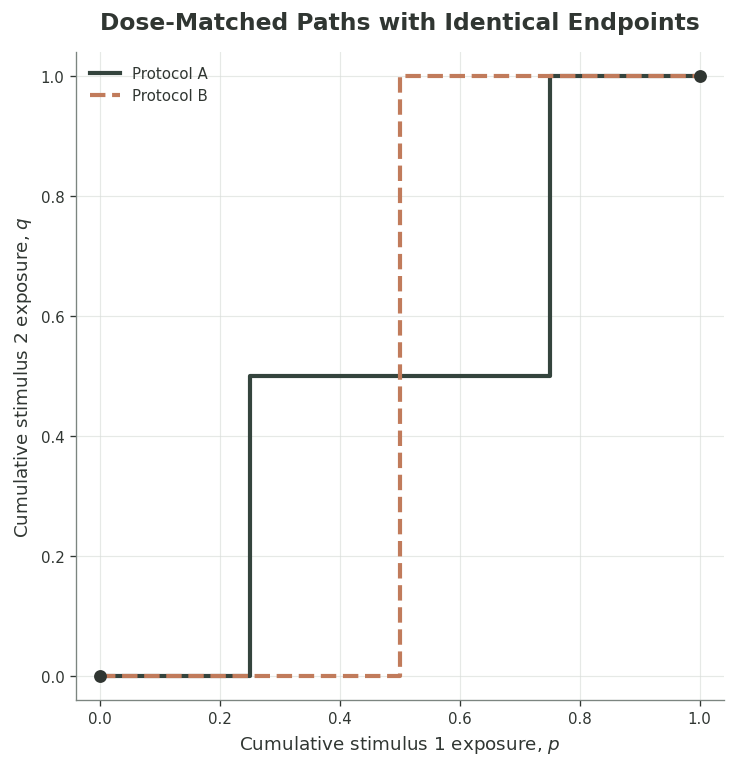

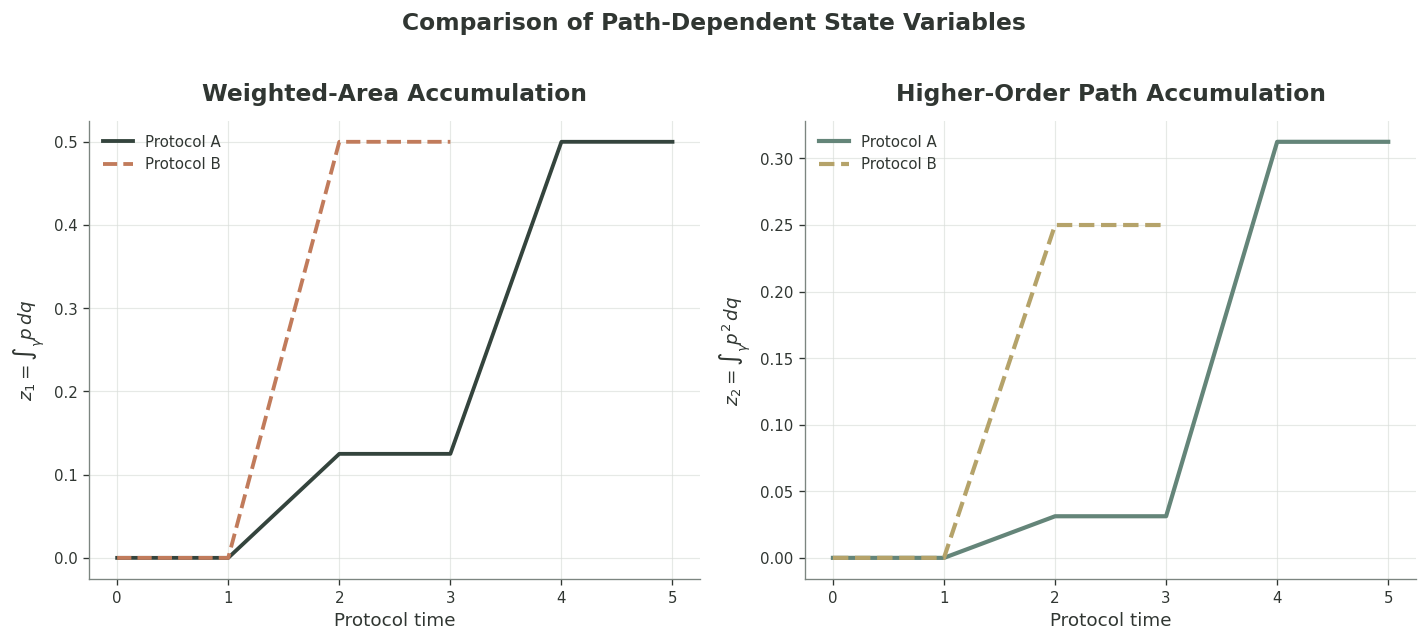

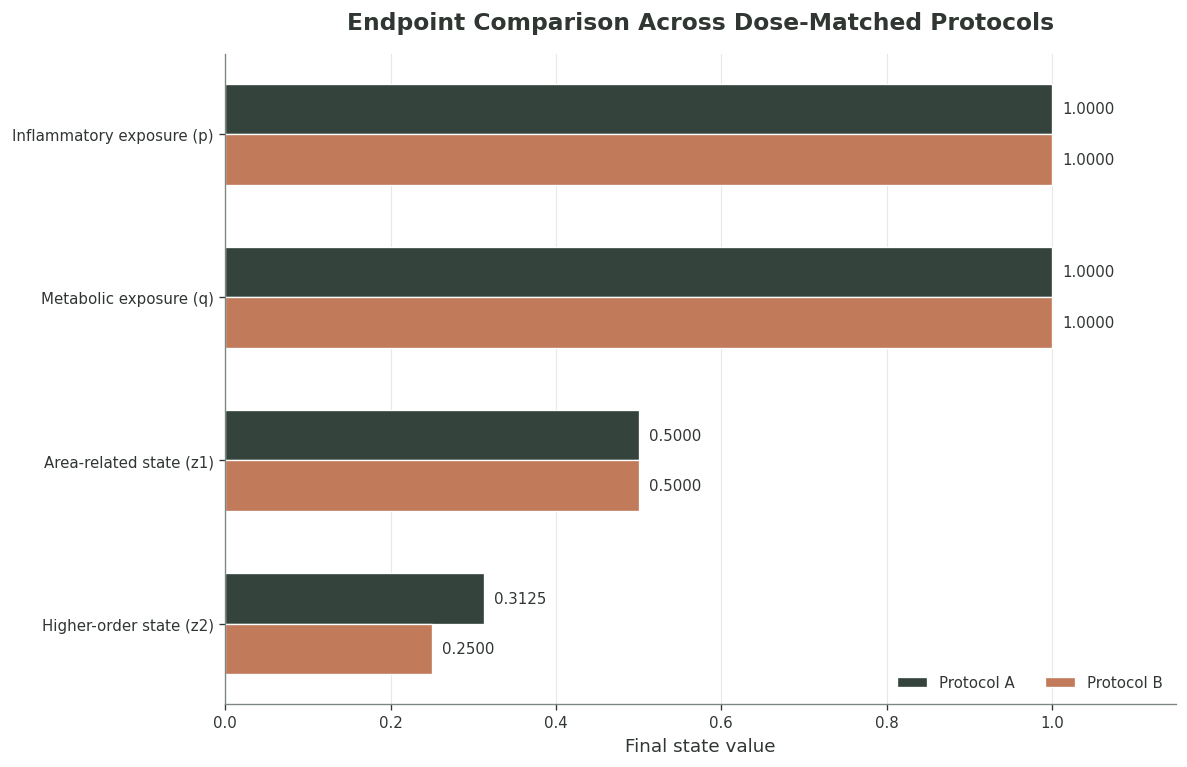

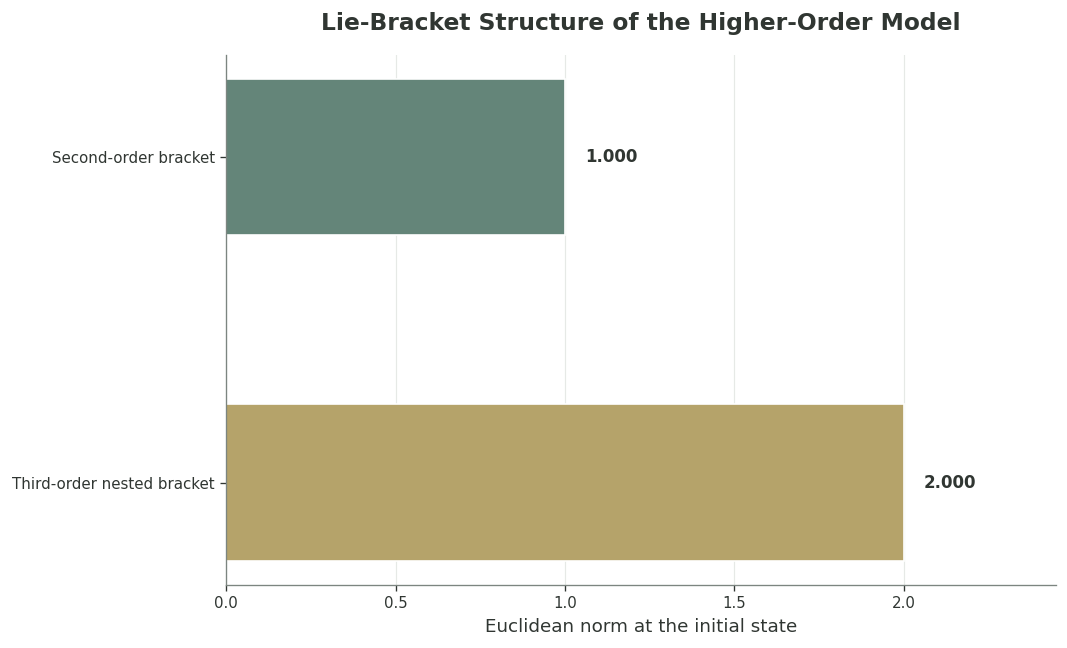


PHASE 4B COMPLETED

PROTOCOL A
---------------------------------------------------------------------------
Final state: [1.     1.     0.5    0.3125]

PROTOCOL B
---------------------------------------------------------------------------
Final state: [1.   1.   0.5  0.25]

DOSE AND AREA COMPARISON
---------------------------------------------------------------------------
Dose difference: [0. 0.]
Weighted-area difference: -2.220446049250e-16

HIGHER-ORDER RESPONSE
---------------------------------------------------------------------------
Numerical difference: 0.062500000000
Analytical difference: 0.062500000000
Absolute error: 2.220446049250e-16

LIE-BRACKET STRUCTURE
---------------------------------------------------------------------------
Second-order bracket: [0. 0. 1. 0.]
Nested third-order bracket: [0. 0. 0. 2.]

VALIDATION
---------------------------------------------------------------------------
Protocol A analytical agreement: PASSED
Protocol B analytical agreement: PASSED

In [15]:

# ============================================================
# BIOLOGICAL SEQUENCE GEOMETRY
# PHASE 4B: HIGHER-ORDER PATH DEPENDENCE
#
# Equal dose
# Equal endpoints
# Equal weighted-area integral
# Different higher-order path response
#
# Numerical integration: scipy.solve_ivp (DOP853)
# All quantities are illustrative and dimensionless.
# No experimental data are used or fitted.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp


# ============================================================
# 2. OUTPUT DIRECTORY AND NUMERICAL SETTINGS
# ============================================================

OUTPUT_DIR = "biological_sequence_geometry_phase4B_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

RTOL = 1e-12
ATOL = 1e-14

POINTS_PER_SEGMENT = 80


# ============================================================
# 3. PUBLICATION-STYLE GRAPH SETTINGS
# ============================================================

COLOR_A = "#34443D"       # Deep charcoal green
COLOR_B = "#C17B5B"       # Terracotta
COLOR_SAGE = "#648579"    # Muted sage
COLOR_OCHRE = "#B5A36A"   # Muted ochre
COLOR_TEXT = "#303632"
COLOR_GRID = "#D9DEDA"
COLOR_BACKGROUND = "#FFFFFF"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelcolor": COLOR_TEXT,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": COLOR_TEXT,
    "axes.edgecolor": "#7C8580",
    "axes.linewidth": 0.8,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.facecolor": COLOR_BACKGROUND,
    "figure.facecolor": COLOR_BACKGROUND
})


def style_axes(ax, grid_axis="both"):

    ax.set_facecolor(COLOR_BACKGROUND)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#7C8580")
    ax.spines["bottom"].set_color("#7C8580")

    ax.tick_params(
        axis="both",
        colors=COLOR_TEXT,
        labelsize=9
    )

    ax.xaxis.label.set_color(COLOR_TEXT)
    ax.yaxis.label.set_color(COLOR_TEXT)

    ax.grid(
        axis=grid_axis,
        color=COLOR_GRID,
        linewidth=0.7,
        alpha=0.65
    )

    ax.set_axisbelow(True)


# ============================================================
# 4. MATHEMATICAL MODEL
# ============================================================

"""
State vector:

    x = (p, q, z1, z2)

Dynamics:

    dp/dt  = u1
    dq/dt  = u2
    dz1/dt = p*u2
    dz2/dt = p^2*u2

Integral representations:

    z1(T) = integral_gamma p dq

    z2(T) = integral_gamma p^2 dq

Control-affine representation:

    dx/dt = u1*F1(x) + u2*F2(x)

where:

    F1 = (1, 0, 0, 0)

    F2 = (0, 1, p, p^2)
"""


def F1(x):

    return np.array([
        1.0,
        0.0,
        0.0,
        0.0
    ])


def F2(x):

    p, q, z1, z2 = x

    return np.array([
        0.0,
        1.0,
        p,
        p**2
    ])


def rhs(t, x, u1, u2):

    return (
        u1 * F1(x)
        + u2 * F2(x)
    )


# ============================================================
# 5. DEFINE DOSE-MATCHED PROTOCOLS
# ============================================================

"""
Each segment is represented by:

    (increment in p, increment in q)

Each segment has unit duration.

Protocol A:

    (0.25, 0)
    (0, 0.50)
    (0.50, 0)
    (0, 0.50)
    (0.25, 0)

Protocol B:

    (0.50, 0)
    (0, 1.00)
    (0.50, 0)

Both protocols have:

    Final p = 1
    Final q = 1

Analytical results:

    Protocol A:
        z1 = 0.5000
        z2 = 0.3125

    Protocol B:
        z1 = 0.5000
        z2 = 0.2500
"""

PROTOCOL_A = [
    (0.25, 0.00),
    (0.00, 0.50),
    (0.50, 0.00),
    (0.00, 0.50),
    (0.25, 0.00)
]

PROTOCOL_B = [
    (0.50, 0.00),
    (0.00, 1.00),
    (0.50, 0.00)
]


# ============================================================
# 6. NUMERICAL INTEGRATION FUNCTION
# ============================================================

def simulate_protocol(
    protocol,
    label,
    points_per_segment=POINTS_PER_SEGMENT
):

    x = np.zeros(4)

    history = {
        "time": [],
        "p": [],
        "q": [],
        "z1": [],
        "z2": []
    }

    global_time = 0.0

    for dp, dq in protocol:

        u1 = float(dp)
        u2 = float(dq)

        if u1 < 0 or u2 < 0:

            raise ValueError(
                "Stimulus controls must be nonnegative."
            )

        def local_rhs(t, state):

            return rhs(
                t,
                state,
                u1,
                u2
            )

        evaluation_times = np.linspace(
            0.0,
            1.0,
            points_per_segment
        )

        solution = solve_ivp(
            local_rhs,
            (0.0, 1.0),
            x,
            method="DOP853",
            t_eval=evaluation_times,
            rtol=RTOL,
            atol=ATOL
        )

        if not solution.success:

            raise RuntimeError(
                f"Integration failed for {label}: "
                f"{solution.message}"
            )

        start_index = (
            0 if len(history["time"]) == 0 else 1
        )

        for j in range(
            start_index,
            len(solution.t)
        ):

            history["time"].append(
                global_time + solution.t[j]
            )

            history["p"].append(
                solution.y[0, j]
            )

            history["q"].append(
                solution.y[1, j]
            )

            history["z1"].append(
                solution.y[2, j]
            )

            history["z2"].append(
                solution.y[3, j]
            )

        x = solution.y[:, -1]

        global_time += 1.0

    for key in history:

        history[key] = np.asarray(
            history[key]
        )

    return {
        "label": label,
        "final_state": x,
        "history": history,
        "duration": global_time
    }


# ============================================================
# 7. RUN BOTH PROTOCOLS
# ============================================================

result_A = simulate_protocol(
    PROTOCOL_A,
    "Protocol A"
)

result_B = simulate_protocol(
    PROTOCOL_B,
    "Protocol B"
)

X_A = result_A["final_state"]
X_B = result_B["final_state"]


# ============================================================
# 8. ANALYTICAL REFERENCE SOLUTIONS
# ============================================================

ANALYTICAL_A = np.array([
    1.0000,
    1.0000,
    0.5000,
    0.3125
])

ANALYTICAL_B = np.array([
    1.0000,
    1.0000,
    0.5000,
    0.2500
])

ANALYTICAL_HIGHER_ORDER_DIFFERENCE = 0.0625


# ============================================================
# 9. NUMERICAL ERROR AND CONSISTENCY CHECKS
# ============================================================

NUMERICAL_DIFFERENCE = X_A - X_B

DOSE_DIFFERENCE = NUMERICAL_DIFFERENCE[:2]

AREA_DIFFERENCE = X_A[2] - X_B[2]

HIGHER_ORDER_DIFFERENCE = X_A[3] - X_B[3]

ENDPOINT_ERROR_A = np.max(
    np.abs(X_A - ANALYTICAL_A)
)

ENDPOINT_ERROR_B = np.max(
    np.abs(X_B - ANALYTICAL_B)
)

DOSE_ERROR = np.max(
    np.abs(DOSE_DIFFERENCE)
)

AREA_ERROR = abs(
    AREA_DIFFERENCE
)

HIGHER_ORDER_ERROR = abs(
    HIGHER_ORDER_DIFFERENCE
    - ANALYTICAL_HIGHER_ORDER_DIFFERENCE
)


# ============================================================
# 10. LIE-BRACKET CALCULATIONS
# ============================================================

"""
Bracket convention:

    [F1,F2] = DF2*F1 - DF1*F2

For the present system:

    [F1,F2] = (0,0,1,2p)

Nested bracket:

    [F1,[F1,F2]] = (0,0,0,2)

The second-order bracket acts on z1.

The nested third-order bracket acts on z2.
"""


def bracket_F1_F2(x):

    p, q, z1, z2 = x

    return np.array([
        0.0,
        0.0,
        1.0,
        2.0 * p
    ])


def nested_bracket_F1_F1F2(x):

    return np.array([
        0.0,
        0.0,
        0.0,
        2.0
    ])


INITIAL_STATE = np.zeros(4)

BRACKET_SECOND = bracket_F1_F2(
    INITIAL_STATE
)

BRACKET_THIRD = nested_bracket_F1_F1F2(
    INITIAL_STATE
)

BRACKET_SECOND_NORM = np.linalg.norm(
    BRACKET_SECOND
)

BRACKET_THIRD_NORM = np.linalg.norm(
    BRACKET_THIRD
)


# ============================================================
# 11. VALIDATION
# ============================================================

assert np.allclose(
    X_A,
    ANALYTICAL_A,
    rtol=0,
    atol=1e-10
)

assert np.allclose(
    X_B,
    ANALYTICAL_B,
    rtol=0,
    atol=1e-10
)

assert np.allclose(
    X_A[:2],
    X_B[:2],
    rtol=0,
    atol=1e-10
)

assert np.isclose(
    X_A[2],
    X_B[2],
    rtol=0,
    atol=1e-10
)

assert np.isclose(
    HIGHER_ORDER_DIFFERENCE,
    ANALYTICAL_HIGHER_ORDER_DIFFERENCE,
    rtol=0,
    atol=1e-10
)

assert np.all(np.isfinite(X_A))
assert np.all(np.isfinite(X_B))

assert np.all(X_A >= 0)
assert np.all(X_B >= 0)

assert np.isclose(
    BRACKET_SECOND_NORM,
    1.0
)

assert np.isclose(
    BRACKET_THIRD_NORM,
    2.0
)


# ============================================================
# 12. FIGURE 1: DOSE-MATCHED PATHS
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.5, 6.5),
    facecolor=COLOR_BACKGROUND
)

ax.plot(
    result_A["history"]["p"],
    result_A["history"]["q"],
    color=COLOR_A,
    linewidth=2.5,
    label="Protocol A"
)

ax.plot(
    result_B["history"]["p"],
    result_B["history"]["q"],
    color=COLOR_B,
    linewidth=2.5,
    linestyle="--",
    label="Protocol B"
)

ax.scatter(
    [0, 1],
    [0, 1],
    color=COLOR_TEXT,
    s=45,
    zorder=5
)

ax.set_xlabel(
    r"Cumulative stimulus 1 exposure, $p$"
)

ax.set_ylabel(
    r"Cumulative stimulus 2 exposure, $q$"
)

ax.set_title(
    "Dose-Matched Paths with Identical Endpoints",
    fontweight="bold",
    pad=14
)

ax.set_xlim(-0.04, 1.04)
ax.set_ylim(-0.04, 1.04)

ax.set_aspect("equal", adjustable="box")

style_axes(ax, "both")

ax.legend(
    frameon=False,
    loc="upper left"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure1_dose_matched_paths.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 13. FIGURE 2: PATH-DEPENDENT STATE VARIABLES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5.2),
    facecolor=COLOR_BACKGROUND
)

# z1
axes[0].plot(
    result_A["history"]["time"],
    result_A["history"]["z1"],
    color=COLOR_A,
    linewidth=2.3,
    label="Protocol A"
)

axes[0].plot(
    result_B["history"]["time"],
    result_B["history"]["z1"],
    color=COLOR_B,
    linewidth=2.3,
    linestyle="--",
    label="Protocol B"
)

axes[0].set_xlabel("Protocol time")

axes[0].set_ylabel(
    r"$z_1=\int_\gamma p\,dq$"
)

axes[0].set_title(
    "Weighted-Area Accumulation",
    fontweight="bold",
    pad=12
)

style_axes(axes[0], "both")

axes[0].legend(frameon=False)


# z2
axes[1].plot(
    result_A["history"]["time"],
    result_A["history"]["z2"],
    color=COLOR_SAGE,
    linewidth=2.5,
    label="Protocol A"
)

axes[1].plot(
    result_B["history"]["time"],
    result_B["history"]["z2"],
    color=COLOR_OCHRE,
    linewidth=2.5,
    linestyle="--",
    label="Protocol B"
)

axes[1].set_xlabel("Protocol time")

axes[1].set_ylabel(
    r"$z_2=\int_\gamma p^2\,dq$"
)

axes[1].set_title(
    "Higher-Order Path Accumulation",
    fontweight="bold",
    pad=12
)

style_axes(axes[1], "both")

axes[1].legend(frameon=False)

fig.suptitle(
    "Comparison of Path-Dependent State Variables",
    fontsize=14,
    fontweight="bold",
    color=COLOR_TEXT,
    y=1.02
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure2_path_dependent_states.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 14. FIGURE 3: ENDPOINT COMPARISON
# ============================================================

endpoint_names = [
    "Inflammatory exposure (p)",
    "Metabolic exposure (q)",
    "Area-related state (z1)",
    "Higher-order state (z2)"
]

values_A = X_A
values_B = X_B

y = np.arange(
    len(endpoint_names)
)

height = 0.31

fig, ax = plt.subplots(
    figsize=(10, 6.5),
    facecolor=COLOR_BACKGROUND
)

bars_A = ax.barh(
    y - height / 2,
    values_A,
    height=height,
    color=COLOR_A,
    edgecolor="white",
    linewidth=0.8,
    label="Protocol A"
)

bars_B = ax.barh(
    y + height / 2,
    values_B,
    height=height,
    color=COLOR_B,
    edgecolor="white",
    linewidth=0.8,
    label="Protocol B"
)

ax.set_yticks(y)
ax.set_yticklabels(endpoint_names)

ax.invert_yaxis()

ax.set_xlim(0, 1.15)

ax.set_xlabel(
    "Final state value"
)

ax.set_title(
    "Endpoint Comparison Across Dose-Matched Protocols",
    fontweight="bold",
    pad=15
)

for bars in [bars_A, bars_B]:

    for bar in bars:

        value = bar.get_width()

        ax.text(
            value + 0.012,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            ha="left",
            fontsize=9,
            color=COLOR_TEXT
        )

style_axes(ax, "x")

ax.legend(
    frameon=False,
    loc="lower right",
    ncol=2
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure3_endpoint_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 15. FIGURE 4: LIE-BRACKET STRUCTURE
# ============================================================

bracket_labels = [
    "Second-order bracket",
    "Third-order nested bracket"
]

bracket_values = [
    BRACKET_SECOND_NORM,
    BRACKET_THIRD_NORM
]

bracket_colors = [
    COLOR_SAGE,
    COLOR_OCHRE
]

y_bracket = np.arange(
    len(bracket_labels)
)

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    facecolor=COLOR_BACKGROUND
)

bars = ax.barh(
    y_bracket,
    bracket_values,
    height=0.48,
    color=bracket_colors,
    edgecolor="white",
    linewidth=1.0
)

ax.set_yticks(y_bracket)
ax.set_yticklabels(bracket_labels)

ax.invert_yaxis()

ax.set_xlim(0, 2.45)

ax.set_xlabel(
    "Euclidean norm at the initial state"
)

ax.set_title(
    "Lie-Bracket Structure of the Higher-Order Model",
    fontweight="bold",
    pad=15
)

for bar in bars:

    value = bar.get_width()

    ax.text(
        value + 0.06,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=COLOR_TEXT
    )

style_axes(ax, "x")

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figure4_lie_bracket_structure.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 16. SAVE ENDPOINT DATA
# ============================================================

endpoint_data = np.column_stack([
    X_A,
    X_B,
    X_A - X_B
])

np.savetxt(
    os.path.join(
        OUTPUT_DIR,
        "endpoint_comparison.csv"
    ),
    endpoint_data,
    delimiter=",",
    header="Protocol_A,Protocol_B,Difference",
    comments=""
)


# ============================================================
# 17. SAVE SUMMARY REPORT
# ============================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "phase4B_simulation_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "BIOLOGICAL SEQUENCE GEOMETRY\n"
    )

    file.write(
        "PHASE 4B: HIGHER-ORDER PATH DEPENDENCE\n"
    )

    file.write("=" * 75 + "\n\n")

    file.write(
        "All quantities are illustrative and dimensionless.\n"
    )

    file.write(
        "No experimental data were used or fitted.\n\n"
    )

    file.write(
        "PROTOCOL A FINAL STATE\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        np.array2string(
            X_A,
            precision=12
        ) + "\n\n"
    )

    file.write(
        "PROTOCOL B FINAL STATE\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        np.array2string(
            X_B,
            precision=12
        ) + "\n\n"
    )

    file.write(
        "ANALYTICAL REFERENCE\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Protocol A: {ANALYTICAL_A}\n"
    )

    file.write(
        f"Protocol B: {ANALYTICAL_B}\n\n"
    )

    file.write(
        "NUMERICAL DIFFERENCES: A - B\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Dose difference: {DOSE_DIFFERENCE}\n"
    )

    file.write(
        f"Weighted-area difference: "
        f"{AREA_DIFFERENCE:.12e}\n"
    )

    file.write(
        f"Higher-order difference: "
        f"{HIGHER_ORDER_DIFFERENCE:.12f}\n\n"
    )

    file.write(
        "NUMERICAL ERRORS\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Protocol A endpoint error: "
        f"{ENDPOINT_ERROR_A:.12e}\n"
    )

    file.write(
        f"Protocol B endpoint error: "
        f"{ENDPOINT_ERROR_B:.12e}\n"
    )

    file.write(
        f"Dose mismatch: {DOSE_ERROR:.12e}\n"
    )

    file.write(
        f"Area mismatch: {AREA_ERROR:.12e}\n"
    )

    file.write(
        f"Higher-order error: "
        f"{HIGHER_ORDER_ERROR:.12e}\n\n"
    )

    file.write(
        "LIE-BRACKET STRUCTURE\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        f"Second-order bracket: {BRACKET_SECOND}\n"
    )

    file.write(
        f"Nested third-order bracket: {BRACKET_THIRD}\n"
    )

    file.write(
        f"Second-order bracket norm: "
        f"{BRACKET_SECOND_NORM:.8f}\n"
    )

    file.write(
        f"Nested bracket norm: "
        f"{BRACKET_THIRD_NORM:.8f}\n\n"
    )

    file.write(
        "VALIDATION\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        "Equal-dose validation passed.\n"
    )

    file.write(
        "Equal-endpoint validation passed.\n"
    )

    file.write(
        "Equal-weighted-area validation passed.\n"
    )

    file.write(
        "Different higher-order response validated.\n"
    )

    file.write(
        "Analytical-numerical comparison passed.\n\n"
    )

    file.write(
        "INTERPRETATION\n"
    )

    file.write("-" * 75 + "\n")

    file.write(
        "This example establishes higher-order path dependence "
        "for the specified control-affine model.\n"
    )

    file.write(
        "It does not establish biological validation or "
        "a universal biological law.\n"
    )


# ============================================================
# 18. FINAL AUTOMATED VALIDATION
# ============================================================

checks = {
    "Protocol A analytical agreement":
        ENDPOINT_ERROR_A < 1e-10,

    "Protocol B analytical agreement":
        ENDPOINT_ERROR_B < 1e-10,

    "Equal total dose":
        DOSE_ERROR < 1e-10,

    "Equal weighted-area integral":
        AREA_ERROR < 1e-10,

    "Higher-order difference":
        HIGHER_ORDER_ERROR < 1e-10,

    "Finite numerical states":
        np.all(np.isfinite(X_A))
        and np.all(np.isfinite(X_B)),

    "Valid bracket calculations":
        np.isclose(BRACKET_SECOND_NORM, 1.0)
        and np.isclose(BRACKET_THIRD_NORM, 2.0)
}

for check_name, passed in checks.items():

    if not passed:

        raise RuntimeError(
            f"Validation failed: {check_name}"
        )


# ============================================================
# 19. PRINT FINAL RESULTS
# ============================================================

print("\nPHASE 4B COMPLETED")
print("=" * 75)

print("\nPROTOCOL A")
print("-" * 75)
print("Final state:", X_A)

print("\nPROTOCOL B")
print("-" * 75)
print("Final state:", X_B)

print("\nDOSE AND AREA COMPARISON")
print("-" * 75)

print(
    "Dose difference:",
    DOSE_DIFFERENCE
)

print(
    f"Weighted-area difference: "
    f"{AREA_DIFFERENCE:.12e}"
)

print("\nHIGHER-ORDER RESPONSE")
print("-" * 75)

print(
    f"Numerical difference: "
    f"{HIGHER_ORDER_DIFFERENCE:.12f}"
)

print(
    f"Analytical difference: "
    f"{ANALYTICAL_HIGHER_ORDER_DIFFERENCE:.12f}"
)

print(
    f"Absolute error: "
    f"{HIGHER_ORDER_ERROR:.12e}"
)

print("\nLIE-BRACKET STRUCTURE")
print("-" * 75)

print(
    "Second-order bracket:",
    BRACKET_SECOND
)

print(
    "Nested third-order bracket:",
    BRACKET_THIRD
)

print("\nVALIDATION")
print("-" * 75)

for check_name, passed in checks.items():

    status = "PASSED" if passed else "FAILED"

    print(f"{check_name}: {status}")

print("\nOUTPUT DIRECTORY")
print("-" * 75)

print(
    os.path.abspath(OUTPUT_DIR)
)

print("\nGENERATED FILES")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(" -", filename)

print("\nALL PHASE 4B CHECKS PASSED.")
